In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import os
import scipy.stats as stats
from scipy.special import logsumexp
import pandas as pd
import matplotlib.cm as cm
import math
import itertools
import random
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from random import random

from scipy.stats import linregress
from sklearn.linear_model import RANSACRegressor, LinearRegression
from scipy.stats import chi2_contingency, fisher_exact

import time

In [2]:
def tabprint(x):
    return "\t".join(map(str, x))

numb = "31"
tumor = "t"+numb
folder = "/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/"

#infilename = "/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/"+tumor+".bin_count_table_good_cells.txt"
#infilename = "/mnt/wigclust23/data/safe/ranade/binless_clustering/DNA_alone/"+tumor+"/"+tumor+".bin_count_table_with_cluster.txt"
infilename = "/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/"+tumor+".bin_count_table_all_cells.txt"

bincounts = pd.read_csv(infilename, sep = "\t")
#table = pd.read_csv(infilename, sep="\t")
cells = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/"+tumor+".not_broken_final_list.txt", header = None)[0].values
#counts = np.array(table)[:,3:]

In [3]:
table = bincounts[list(bincounts.columns[:5])+list(cells)]

In [4]:
break_points = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/enca"+numb+"_1M.hg19.5k.k50.varbin.short.cbs.txt", sep="\t")

In [5]:
break_points = break_points[break_points["chrom"]!="chrY"]

In [6]:
break_points.head()

,ID,chrom,loc.start,loc.end,num.mark,seg.mean
0,enca31_1M,chr1,0,15185842,25,0.3866
1,enca31_1M,chr1,15737727,16934316,3,0.8524
2,enca31_1M,chr1,17662850,31981088,26,0.0421
3,enca31_1M,chr1,32536150,36461413,8,0.3735
4,enca31_1M,chr1,37027457,64400687,50,0.1802


In [7]:
# seurat_clusters = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/seurat_clusters.txt", header = None,sep = "\t")

In [8]:
normal_cells = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/normal_cells.txt", header = None,sep = "\t")[0].values

In [9]:
normal_cells

array(['AAAACCATTGGTAGAAG', 'AAAACCCCTGCACTATC', 'AAAACCTGAGGTGAAGA',
       'AAAACCTTCCCAGTTGA', 'AAAGCACCTGCACAAGT', 'AAAGCAGACTGGATTGG',
       'AAAGCAGACTGGTCAAG', 'AAAGCATAATTTATTAA', 'AAAGGCAACTTTGCAAC',
       'AAAGGCGATGCACGACA', 'AAAGGCTAACCATTAGG', 'AAATCGAACCGATATCT',
       'AAATCGGACTACTAACA', 'AAATCGGTGCAATATTC', 'AAATCGGTTTTAATTGG',
       'AAATCGTGAACACTAAG', 'AAATCGTTCCCAAATAT', 'AACAAGAAAGGCTGTAA',
       'AACCCGTAACCATATTC', 'AACGATAATTTCACAGC', 'AACGATGAACAAATAGT',
       'AACGATGAAGCGCGTCT', 'AACGATGAGGTACTTCG', 'AACGATTAGGAATCTAC',
       'AACGGGGAACAAAGAAG', 'AACGGGTTGACTAATCA', 'AATAGCAACAAGGGATT',
       'AATAGCGAAATCAGTAC', 'AATAGCGTGCAAGTACA', 'AATGAGGACTGGTGTAA',
       'AATGAGTAACCAAGAGA', 'ACAGGGAAATCCACAAT', 'ACAGGGAGCTTATCACT',
       'ACAGGGATCCGGAATTG', 'ACAGGGATTCCTTCAAG', 'ACAGGGATTTACAATAT',
       'ACAGGGGACCATGATGT', 'ACCAGATAACCAATTGG', 'ACCCTTAACAAGCATAA',
       'ACCCTTGACCATATATA', 'ACCCTTGACTGGAGAAG', 'ACCCTTGATGCATTATT',
       'ACCCTTGGGTTT

In [10]:
len(cells), len(normal_cells)

(977, 319)

In [11]:
normal_cells = [c for c in cells if c in normal_cells]

In [12]:
len(normal_cells)

319

In [13]:
table["normal_average"] = table[normal_cells].sum(axis = 1)/len(normal_cells)

/home/ranade/.local/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  """Entry point for launching an IPython kernel.


In [14]:
table.head()

,chrom,loc.start,loc.end,abstart,abend,AAAACCAAAGGCCAACG,AAAACCAACCTGTGTAA,AAAACCAAGGCCCTAGA,AAAACCATTCAGTCTTA,AAAACCATTGGTAGAAG,...,TTTCGAAGCTTACTAGA,TTTCGAGACTGGGTTAG,TTTCGAGAGGTACATCC,TTTCGATAGCCTAGTGT,TTTTGGAAATCCCGAAT,TTTTGGAGTCACACACA,TTTTGGGGACGTGATGT,TTTTGGGGCTATAGTAC,TTTTGGTGCAGGGTACA,normal_average
0,chr1,0,15185842,0,15185842,187,511,96,287,83,...,108,122,65,73,160,393,130,163,197,141.579937
1,chr1,15737727,16934316,15737727,16934316,27,79,10,43,4,...,15,24,13,8,30,55,18,14,34,14.793103
2,chr1,17662850,31981088,17662850,31981088,163,515,86,212,90,...,85,98,77,86,165,331,90,163,283,153.357367
3,chr1,32536150,36461413,32536150,36461413,71,210,31,95,34,...,31,40,28,27,44,108,35,39,77,45.228840
4,chr1,37027457,64400687,37027457,64400687,339,1056,178,547,205,...,170,268,175,189,382,637,213,430,515,329.181818


In [15]:
data = table[["chrom","abstart", "abend", "normal_average"]].copy()
q_table = table[["chrom","abstart", "abend", "normal_average"]].copy()

In [16]:
totlen = sum(table["normal_average"])

In [17]:
for n in cells:
    
    q_table[n] = table[n]/sum(table[n])
    q_table[n] = (totlen*q_table[n])/(table["normal_average"])
    data[n] = table[n]

In [18]:
def calc_single(not_normal,q_not_normal):
    obs_NV = np.array(not_normal)[:,:].T
    single = q_not_normal.mean(axis = 1).values
    logmult_KV   = np.log(np.concatenate([[single],[single]]))
    #logmixprob_K = np.log(mixprob_K)
    ## multinomial probability is a dot product in log space
    ## that's cool. 
    logprob_single_NK = np.dot(obs_NV, logmult_KV.T)
    logsum_N   = [logsumexp(list(x)) for x in logprob_single_NK]

    single_lik = sum(logsum_N)
    
    return single_lik

In [19]:
def make_seeds(q_not_normal):
    Seeds = []
    for i in range(len(q_not_normal)):
        #print(i)
        s = []
        #l1 = q_not_normal.loc[i].values
        for j in range(len(q_not_normal)):
            l2 = q_not_normal.loc[j].values
            mi, m, mx = min(l2), l2.mean(), max(l2)
            if i==j:
                s.append([(mi+m)/2, (mx+m)/2])
            else:
                s.append([m, m])
        Seeds.append(s)
    return Seeds

In [20]:
def single_random_seed(q_not_normal):
    s = []
        
    for j in range(len(q_not_normal)):
        l2 = q_not_normal.loc[j].values
        mi, mx = min(l2), max(l2)
        s.append([random() * (mx - mi) + mi, random() * (mx - mi) + mi])
    return s

In [21]:
def make_random_seeds(q_not_normal):
    Seeds = []
    for i in range(len(q_not_normal)):
        #print(i)
        s = []
        #l1 = q_not_normal.loc[i].values
        for j in range(len(q_not_normal)):
            l2 = q_not_normal.loc[j].values
            mi, mx = min(l2), max(l2)
            s.append([random() * (mx - mi) + mi, random() * (mx - mi) + mi])
        Seeds.append(s)
    return Seeds

In [22]:
def EM_algorithm(data,s, MIN_DIFF  = 0.001):
    
    obs_NV = np.array(data)[:,:].T
    log_likelihood = -np.Inf
    ## initialize log prob matrix, will be reused for speed.
    #logprob_NK = np.zeros(shape=(N,K))
    ## initialize multinomial emissions probabilities
    ## here, at random
    mult_KV = np.array(s).T
    mult_KV = mult_KV / np.sum(mult_KV, axis=1)[:, np.newaxis]

    #print(mult_KV)
    for i in range(20):
        logmult_KV = np.log(mult_KV)
        #print(logmult_KV)
        #logmixprob_K = np.log(mixprob_K)
        ## multinomial probability is a dot product in log space
        ## that's cool.
        logprob_NK = np.dot(obs_NV, logmult_KV.T)
        #print(logprob_NK)
        logsum_N   = [logsumexp(list(x)) for x in logprob_NK]
        ## by the by, the total of the logsumN is ~ to the the log likelihood.
        ## in effect, what we are trying to maximize.
        logprob_NK = np.add(logprob_NK, -np.array(logsum_N)[:, np.newaxis])
        #print(logprob_NK)

        membership_NK = np.exp(logprob_NK)
        log_likelihood_last = log_likelihood
        log_likelihood = np.sum(logsum_N)

        mult_KV = np.dot(membership_NK.T, obs_NV)
        mult_KV = mult_KV / np.sum(mult_KV, axis=1)[:, np.newaxis]
        #sum_K = np.sum(mult_KV, axis=1)
        #mult_KV = mult_KV / sum_K[:, np.newaxis]
        ## set a lowest possible multinomial value, and renorm
        #mult_KV = np.maximum(mult_KV, MINPROB)
        #sum_K   = np.sum(mult_KV, axis=1)
        log_diff = abs(log_likelihood-log_likelihood_last)
        #print (log_likelihood-log_likelihood_last )
        if log_diff < MIN_DIFF:
            #print ( 'enough already...' )
            break
    if log_diff > 10*MIN_DIFF:
        return logprob_NK, -np.Inf, mult_KV
    
    return logprob_NK, log_likelihood, mult_KV

In [23]:
def alg_on_seeds(data):
    
    q_data = data/data.sum(axis=0)
    obs_NV = np.array(data)[:,:]
    poss_outputs = []
    lik = []
    
    Seeds = make_seeds(q_data)
    
    for s in Seeds:
        logprob_NK, log_lik, mult_KV = EM_algorithm(data,s)
        output = dict(zip(data.columns, logprob_NK))
        poss_outputs.append(logprob_NK)
        lik.append(log_lik)
#         H = plt.hist([x-y for x,y in logprob_NK], bins = 50)
#         plt.show()
    
    return poss_outputs, lik

In [24]:
def alg_on_random_seed(data):
    
    q_data = data/data.sum(axis=0)
    obs_NV = np.array(data)[:,:]
    poss_outputs = []
    lik = []
    
    Seeds = make_random_seeds(q_data)
    
    for s in Seeds:
        logprob_NK, log_lik, mult_KV = EM_algorithm(data,s)
        output = dict(zip(data.columns, logprob_NK))
        poss_outputs.append(logprob_NK)
        lik.append(log_lik)
#         H = plt.hist([x-y for x,y in logprob_NK], bins = 50)
#         plt.show()
    
    return poss_outputs, lik

In [25]:
def alg_on_single_seed(data):
    
    q_data = data/data.sum(axis=0)
    obs_NV = np.array(data)[:,:]
    poss_outputs = []
    lik = []
    
    s = single_random_seed(q_data)
    
    
    logprob_NK, log_lik, mult_KV = EM_algorithm(data,s)
    
    return logprob_NK, log_lik, mult_KV

In [26]:
def ratio_of_ratios(all_data):
    logprob_NK, log_lik, mult_KV = alg_on_single_seed(all_data)
    cluster1 =  np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
    cluster2 =  np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
    cells_1 = [all_data.columns[i] for i in cluster1]
    cells_2 = [all_data.columns[i] for i in cluster2]
#     logmult_KV = np.log(mult_KV)
#     x , y  = logmult_KV[0], logmult_KV[1]

#     distances = np.abs(x - y) / np.sqrt(2)
#     sorted_indices = np.argsort(distances)[::-1]

#     top_n = 10
#     bottom_n = 30
#     top_indices = sorted_indices[:top_n]
#     bottom_indices = sorted_indices[-bottom_n:]
    
    counts_1 = all_data[cells_1].sum(axis = 1)
    counts_2 = all_data[cells_2].sum(axis = 1)
    
    total_1 = np.sum(counts_1)
    total_2 = np.sum(counts_2)

    chi2_values = []
    for i in range(len(counts_1)):
        observed = np.array([
            [counts_1[i], total_1 - counts_1[i]],
            [counts_2[i], total_2 - counts_2[i]]
        ])
        chi2, p, dof, expected = chi2_contingency(observed, correction=False)
        chi2_values.append(chi2)
    chi2_values = np.array(chi2_values)
    top_indices = np.argsort(chi2_values)[-10:][::-1]
    bottom_indices = np.argsort(chi2_values)[:30]
    
    ratios_1 = []
    ratios_2 = []
    for i in top_indices:
        r1 = []
        r2 = []
        for j in bottom_indices:
            if j!=i:
                r1.append(counts_1[i]/counts_1[j])
                r2.append(counts_2[i]/counts_2[j])
        ratios_1.append(r1)
        ratios_2.append(r2)
    slopes = []
    fig,ax = plt.subplots(1, figsize=(10, 10))
    x = np.linspace(0, 10, 50)
    fractions = [(p, q) for p in range(1, 4) for q in range(1, 4) if np.gcd(p, q) == 1 and not (p == 0)]
    for p, q in fractions:
        slope = p / q
        y = slope * x
        if p == q:
            plt.plot(x, y, alpha = 0.2, color = "black")
        else:
            plt.plot(x, y, alpha = 0.2, color = "grey")
        
        
    for r1, r2 in zip(ratios_1, ratios_2): 
    #    fig,ax = plt.subplots(1, figsize=(10, 10))
        plt.scatter(r1, r2, alpha = 0.5)
    for r1, r2 in zip(ratios_1, ratios_2): 

        model = RANSACRegressor(LinearRegression()).fit(np.array(r1).reshape(-1, 1), np.array(r2))
        slopes.append(model.estimator_.coef_[0])
        x_fit = np.linspace(min(r1), max(r1), 100).reshape(-1, 1)
        y_fit = model.predict(x_fit)
        plt.plot(x_fit, y_fit)
    
    plt.xlim([0,10])
    plt.ylim([0,10])
    return slopes, top_indices, bottom_indices, cells_1, cells_2

In [27]:
all_data = data[cells]

In [28]:
q_all_data = (all_data/all_data.sum(axis=0))

In [29]:
q_data = pd.DataFrame()
for name in q_all_data.columns:
    q_data[name] = q_all_data[name]/(data["normal_average"])

In [30]:
#poss_outputs, lik = alg_on_random_seed(all_data)

In [31]:
#poss_outputs1, lik1 = alg_on_seeds(all_data)

In [32]:
# fig,ax = plt.subplots(1, figsize=(20, 10))
# plt.scatter(range(len(lik)),sorted(lik), alpha = 0.5)
# plt.scatter(range(len(lik1)),sorted(lik1), alpha = 0.5)
# #plt.axhline(single_lik)

In [33]:
# fig,ax = plt.subplots(1, figsize=(20, 10))
# plt.scatter(range(len(lik)),sorted(lik))
# #plt.axhline(single_lik)

In [34]:
# logprob_NK = poss_outputs[np.argmax(lik)]
# cluster1 =  np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
# cluster2 =  np.where(np.array([x-y for x,y in logprob_NK])<0)[0]

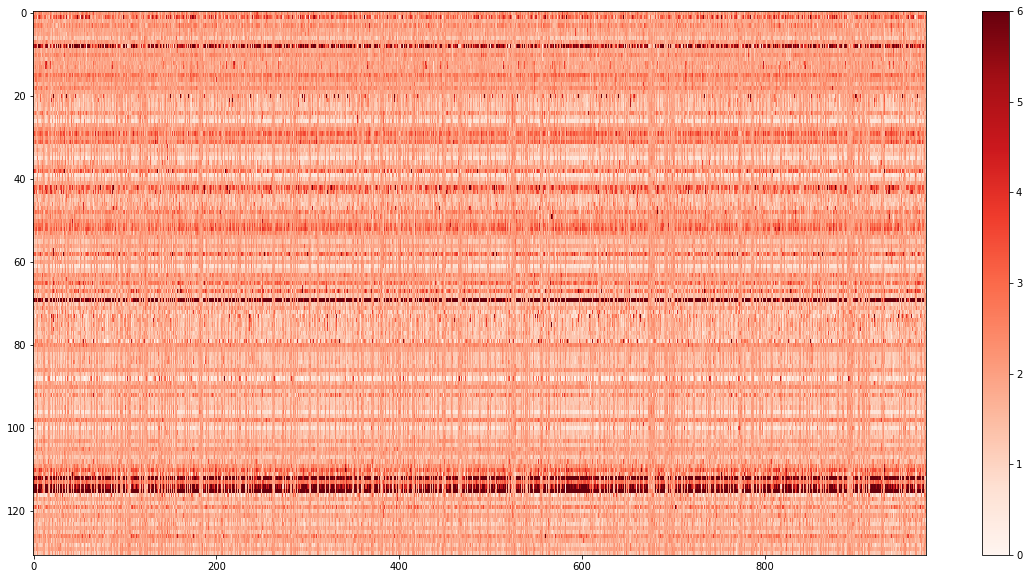

In [35]:
fig,ax = plt.subplots(1,figsize=(20, 10))
h = ax.imshow(2*(q_data/q_data.mean(axis = 0).values), cmap = 'Reds',interpolation='nearest', aspect='auto', vmin=0, vmax=6)
fig.colorbar(h)

In [36]:
#logprob_NK = poss_outputs[np.argmax(lik)]

In [37]:
# H = plt.hist([x-y for x,y in logprob_NK], bins = 50)
# plt.show()

In [38]:
data["lengths"] = data["abend"]-data["abstart"]

In [39]:
logprob_NK, log_lik, mult_KV = alg_on_single_seed(all_data)

In [40]:
cluster1 =  np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
cluster2 =  np.where(np.array([x-y for x,y in logprob_NK])<0)[0]

In [41]:
cells_1 = [all_data.columns[i] for i in cluster1]
cells_2 = [all_data.columns[i] for i in cluster2]

In [42]:
data.head()

,chrom,abstart,abend,normal_average,AAAACCAAAGGCCAACG,AAAACCAACCTGTGTAA,AAAACCAAGGCCCTAGA,AAAACCATTCAGTCTTA,AAAACCATTGGTAGAAG,AAAACCCCTGCACTATC,...,TTTCGAAGCTTACTAGA,TTTCGAGACTGGGTTAG,TTTCGAGAGGTACATCC,TTTCGATAGCCTAGTGT,TTTTGGAAATCCCGAAT,TTTTGGAGTCACACACA,TTTTGGGGACGTGATGT,TTTTGGGGCTATAGTAC,TTTTGGTGCAGGGTACA,lengths
0,chr1,0,15185842,141.579937,187,511,96,287,83,108,...,108,122,65,73,160,393,130,163,197,15185842
1,chr1,15737727,16934316,14.793103,27,79,10,43,4,7,...,15,24,13,8,30,55,18,14,34,1196589
2,chr1,17662850,31981088,153.357367,163,515,86,212,90,109,...,85,98,77,86,165,331,90,163,283,14318238
3,chr1,32536150,36461413,45.228840,71,210,31,95,34,38,...,31,40,28,27,44,108,35,39,77,3925263
4,chr1,37027457,64400687,329.181818,339,1056,178,547,205,220,...,170,268,175,189,382,637,213,430,515,27373230


In [43]:
logmult_KV = np.log(mult_KV)

In [44]:
x , y  = logmult_KV[0], logmult_KV[1]

distances = np.abs(x - y) / np.sqrt(2)
sorted_indices = np.argsort(distances)[::-1]

top_n = 10
bottom_n = 30
top_indices = sorted_indices[:top_n]
bottom_indices = sorted_indices[-bottom_n:]

In [45]:
top_indices

array([ 69, 115, 112, 114,   8,  39,  35, 100,  61,  96])

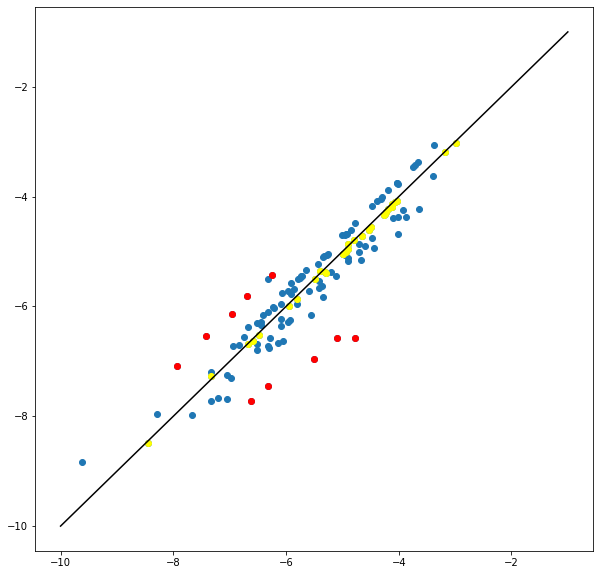

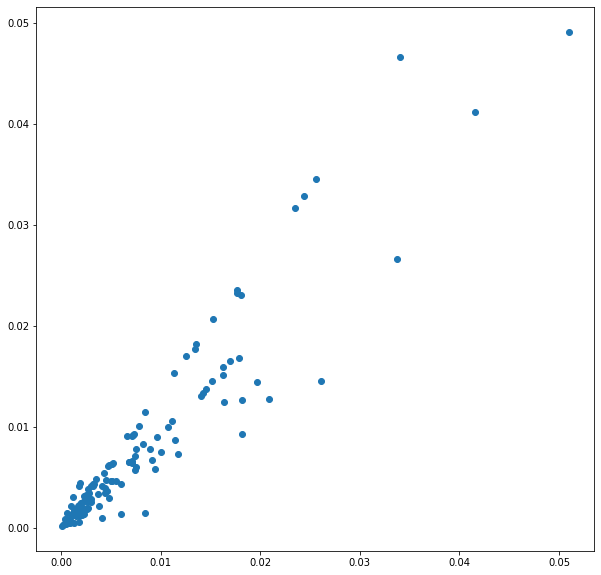

In [46]:
fig,ax = plt.subplots(1, figsize=(10, 10))
plt.scatter(logmult_KV[0], logmult_KV[1])
plt.scatter(x[top_indices], y[top_indices], color='red', label='Most different')
plt.scatter(x[bottom_indices], y[bottom_indices], color='yellow', label='Most alike')

plt.plot(range(-10,0), range(-10,0), color = "black", )
fig,ax = plt.subplots(1, figsize=(10, 10))
plt.scatter(mult_KV[0], mult_KV[1])


In [47]:
# counts_1 = all_data[cells_1].sum(axis = 1)/data["lengths"]
# counts_2 = all_data[cells_2].sum(axis = 1)/data["lengths"]

counts_1 = all_data[cells_1].sum(axis = 1)
counts_2 = all_data[cells_2].sum(axis = 1)

# counts_1 = all_data[cells_1].sum(axis = 1)/data["normal_average"]
# counts_2 = all_data[cells_2].sum(axis = 1)/data["normal_average"]

In [48]:
total_1 = np.sum(counts_1)
total_2 = np.sum(counts_2)

chi2_values = []
for i in range(len(counts_1)):
    observed = np.array([
        [counts_1[i], total_1 - counts_1[i]],
        [counts_2[i], total_2 - counts_2[i]]
    ])
    chi2, p, dof, expected = chi2_contingency(observed, correction=False)
    chi2_values.append(chi2)
chi2_values = np.array(chi2_values)
top_chi2 = np.argsort(chi2_values)[-10:][::-1]
bottom_chi2 = np.argsort(chi2_values)[:30]

In [49]:
top_chi2 = np.argsort(chi2_values)[-10:][::-1]

bottom_chi2 = np.argsort(chi2_values)[:30]

In [50]:
#print(sorted(chi2_values)[-10:])
print(sorted(chi2_values)[:30])

[1.2347704882767845, 1.309828535333217, 1.6652277421567565, 3.8015404102053467, 20.35386628651022, 21.437405834176072, 29.50277919110652, 35.53770487574259, 38.36445529854197, 69.47373181177147, 71.49805021799699, 75.88733774343667, 92.62058830352703, 127.51852412983698, 135.7827715593836, 158.52526233694954, 171.98908620145153, 173.50528465387941, 177.28129449680904, 179.32518036614994, 183.20491843870164, 238.87192963743328, 247.56187546643991, 264.42963071802194, 292.1472047457169, 296.26716513578947, 296.395309707502, 312.46327013040235, 313.02028005239345, 321.5348121135722]


In [51]:
print(top_indices)
print(top_chi2)
print(bottom_indices)
print(bottom_chi2)

[ 69 115 112 114   8  39  35 100  61  96]
[ 69  52  42 115  34  31 112  93 130  94]
[117  73  54  37 127   4   2  14  64  49  81  56  60 124 106   9  21 108
 129  17  71  19  74   5  79  11  47  27  41  89]
[ 89  79  47  27  71 108  41  73  17  11  74  21  49   5  72 106  33 124
 122   2  56 129   9  92  24 116 127 111 103  14]


In [52]:
min(chi2_values), max(chi2_values)

(1.2347704882767845, 62641.95590132944)

(array([61., 16.,  9.,  7.,  4.,  4.,  3.,  2.,  2.,  2.,  4.,  3.,  2.,
         0.,  1.,  1.,  0.,  1.,  1.,  2.,  0.,  0.,  0.,  1.,  0.,  0.,
         0.,  0.,  1.,  0.,  1.,  0.,  0.,  1.,  0.,  0.,  0.,  0.,  0.,
         1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.]),
 array([1.23477049e+00, 1.25404919e+03, 2.50686362e+03, 3.75967804e+03,
        5.01249246e+03, 6.26530688e+03, 7.51812131e+03, 8.77093573e+03,
        1.00237502e+04, 1.12765646e+04, 1.25293790e+04, 1.37821934e+04,
        1.50350078e+04, 1.62878223e+04, 1.75406367e+04, 1.87934511e+04,
        2.00462655e+04, 2.12990800e+04, 2.25518944e+04, 2.38047088e+04,
        2.50575232e+04, 2.63103376e+04, 2.75631521e+04, 2.88159665e+04,
        3.00687809e+04, 3.13215953e+04, 3.25744098e+04, 3.38272242e+04,
        3.50800386e+04, 3.63328530e+04, 3.75856674e+04, 3.88384819e+04,
        4.00912963e+04, 4.13441107e+04, 4.25969251e+04, 4.38497396e+04,
        4.51025540e+04, 4.63553684e+04, 4.76081828e+04, 4.88609973e+

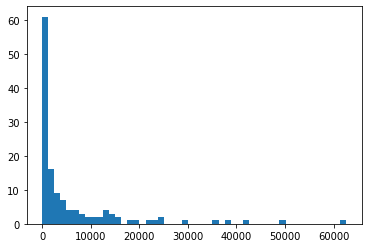

In [53]:
plt.hist(chi2_values, bins = 50)
#plt.xlim([0,1000])

(array([47., 25., 17.,  9.,  6.,  7.,  7.,  4.,  1.,  2.,  2.,  0.,  0.,
         2.,  0.,  0.,  1.,  0.,  0.,  1.]),
 array([   1986. ,   77592.6,  153199.2,  228805.8,  304412.4,  380019. ,
         455625.6,  531232.2,  606838.8,  682445.4,  758052. ,  833658.6,
         909265.2,  984871.8, 1060478.4, 1136085. , 1211691.6, 1287298.2,
        1362904.8, 1438511.4, 1514118. ]),
 <BarContainer object of 20 artists>)

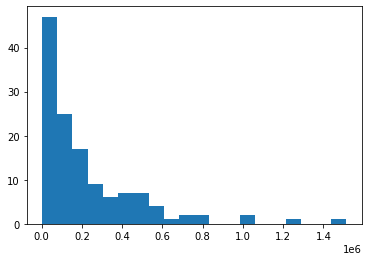

In [54]:
plt.hist(counts_1, bins = 20)

In [55]:
ratios_1 = []
ratios_2 = []
for pair in itertools.combinations(range(len(all_data)),2):
    i,j = pair
    ratios_1.append(counts_1[i]/counts_1[j])
    ratios_2.append(counts_2[i]/counts_2[j])

In [56]:
len(ratios_1)

8515

(0.0, 50.0)

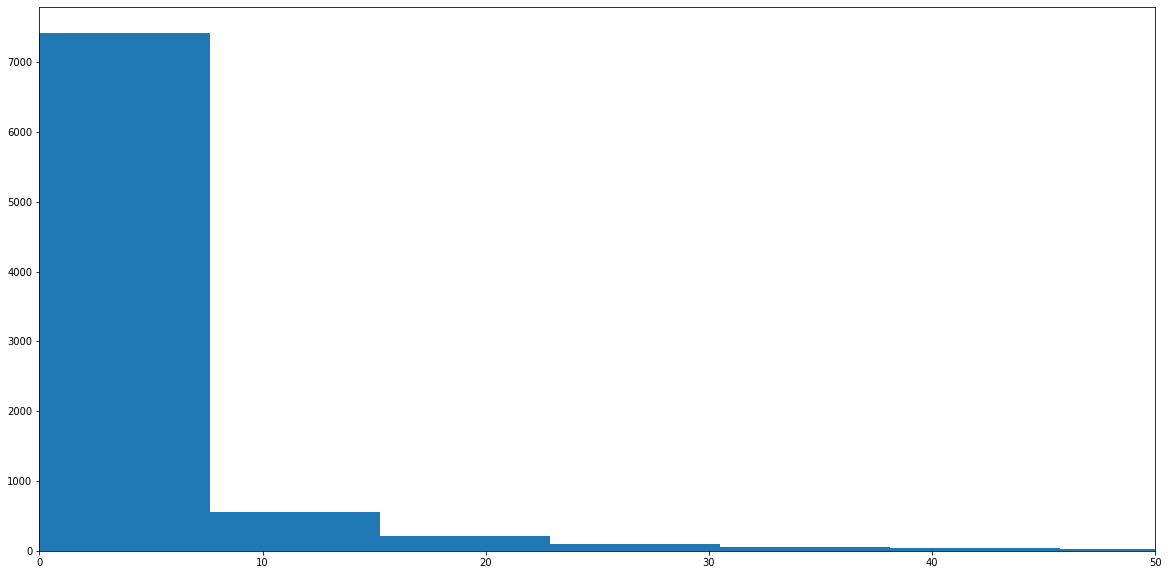

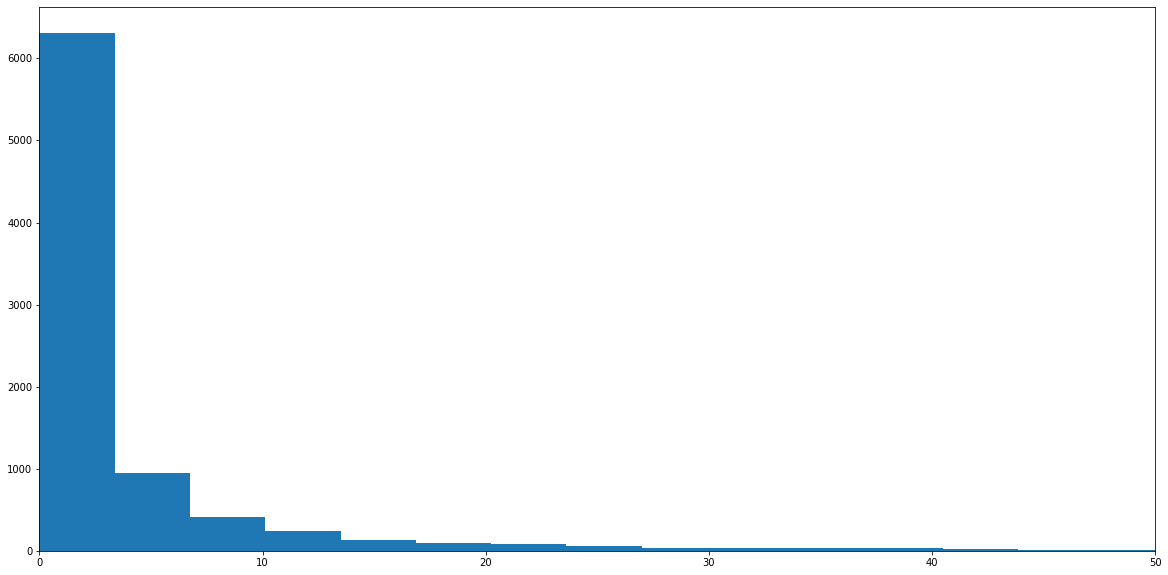

In [57]:
fig,ax = plt.subplots(1, figsize=(20, 10))
plt.hist(ratios_1, bins = 100)
plt.xlim([0,50])
fig,ax = plt.subplots(1, figsize=(20, 10))
plt.hist(ratios_2, bins = 100)
plt.xlim([0,50])

(0.0, 2.0)

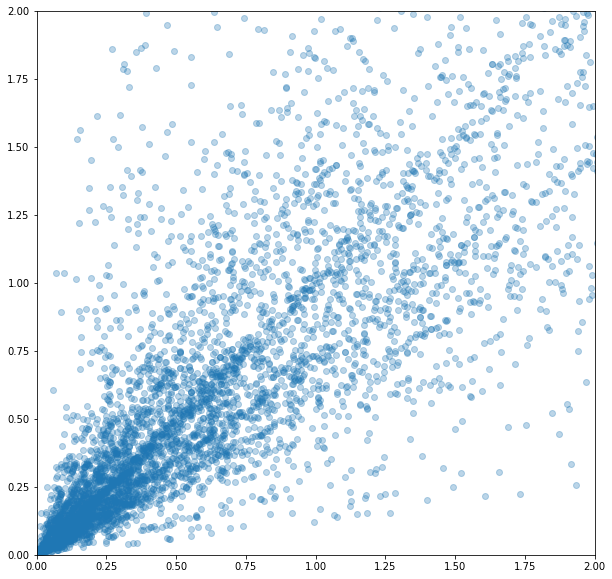

In [58]:
fig,ax = plt.subplots(1, figsize=(10, 10))
plt.scatter(ratios_1, ratios_2, alpha = 0.3)
plt.xlim([0,2])
plt.ylim([0,2])

In [59]:
ratios_1 = []
ratios_2 = []
for i in top_indices:
    r1 = []
    r2 = []
    for j in bottom_indices:
        if j!=i:
            r1.append(counts_1[i]/counts_1[j])
            r2.append(counts_2[i]/counts_2[j])
    ratios_1.append(r1)
    ratios_2.append(r2)

In [60]:
fisher_exact_1 = []
p_vals_1 = []
count = 0
for i in top_indices:
    for j in bottom_indices:
        print(i,j)
        
        ratios_1.append(counts_1[i]/counts_1[j])
        ratios_2.append(counts_2[i]/counts_2[j])

        res = fisher_exact(np.array([[counts_1[i],counts_1[j]],[counts_2[i],counts_2[j]]]), alternative='two-sided')
        fisher_exact_1.append(res)
        p_vals_1.append(res[1])

69 117
69 73
69 54
69 37
69 127
69 4
69 2
69 14
69 64
69 49
69 81
69 56
69 60
69 124
69 106
69 9
69 21
69 108
69 129
69 17
69 71
69 19
69 74
69 5
69 79
69 11
69 47
69 27
69 41
69 89
115 117
115 73
115 54
115 37
115 127
115 4
115 2
115 14
115 64
115 49
115 81
115 56
115 60
115 124
115 106
115 9
115 21
115 108
115 129
115 17
115 71
115 19
115 74
115 5
115 79
115 11
115 47
115 27
115 41
115 89
112 117
112 73
112 54
112 37
112 127
112 4
112 2
112 14
112 64
112 49
112 81
112 56
112 60
112 124
112 106
112 9
112 21
112 108
112 129
112 17
112 71
112 19
112 74
112 5
112 79
112 11
112 47
112 27
112 41
112 89
114 117
114 73
114 54
114 37
114 127
114 4
114 2
114 14
114 64
114 49
114 81
114 56
114 60
114 124
114 106
114 9
114 21
114 108
114 129
114 17
114 71
114 19
114 74
114 5
114 79
114 11
114 47
114 27
114 41
114 89
8 117
8 73
8 54
8 37
8 127
8 4
8 2
8 14
8 64
8 49
8 81
8 56
8 60
8 124
8 106
8 9
8 21
8 108
8 129
8 17
8 71
8 19
8 74
8 5
8 79
8 11
8 47
8 27
8 41
8 89
39 117
39 73
39 54
39 37
39 12

(0.0, 2.0)

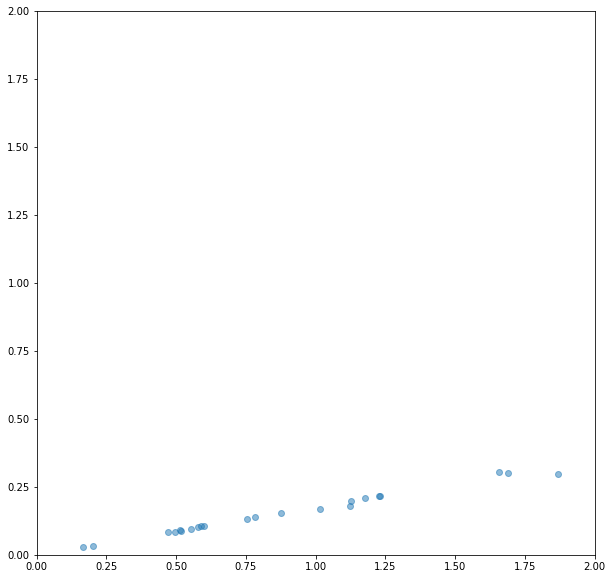

In [61]:
fig,ax = plt.subplots(1, figsize=(10, 10))
plt.scatter(ratios_1[0], ratios_2[0], alpha = 0.5)
plt.xlim([0,2])
plt.ylim([0,2])

(0.0, 2.0)

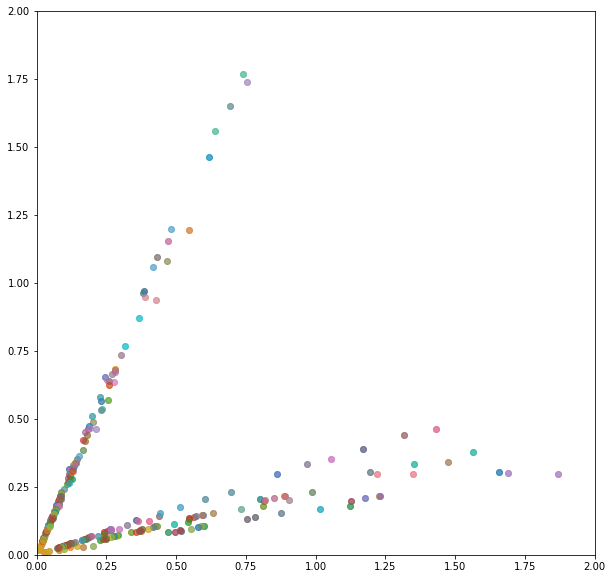

In [62]:
fig,ax = plt.subplots(1, figsize=(10, 10))
for r1, r2 in zip(ratios_1, ratios_2): 
#    fig,ax = plt.subplots(1, figsize=(10, 10))
    plt.scatter(r1, r2, alpha = 0.5)
plt.xlim([0,2])
plt.ylim([0,2])

In [63]:
# slopes = []
# fig,ax = plt.subplots(1, figsize=(10, 10))
# for r1, r2 in zip(ratios_1, ratios_2): 
# #    fig,ax = plt.subplots(1, figsize=(10, 10))
#     plt.scatter(r1, r2, alpha = 0.5)
# for r1, r2 in zip(ratios_1, ratios_2):
    
    
#     model = RANSACRegressor(LinearRegression()).fit(np.array(r1).reshape(-1, 1), np.array(r2))
#     slopes.append(model.estimator_.coef_[0])
#     x_fit = np.linspace(min(r1), max(r1), 100).reshape(-1, 1)
#     y_fit = model.predict(x_fit)
#     plt.plot(x_fit, y_fit)
# # plt.xlim([0,2])
# # plt.ylim([0,2])

In [64]:
#slopes

In [65]:
ratios_1 = []
ratios_2 = []
for i in top_indices:
    r1 = []
    r2 = []
    for j in range(len(all_data)):
        if j!=i:
            r1.append(counts_1[i]/counts_1[j])
            r2.append(counts_2[i]/counts_2[j])
    ratios_1.append(r1)
    ratios_2.append(r2)

(0.0, 2.0)

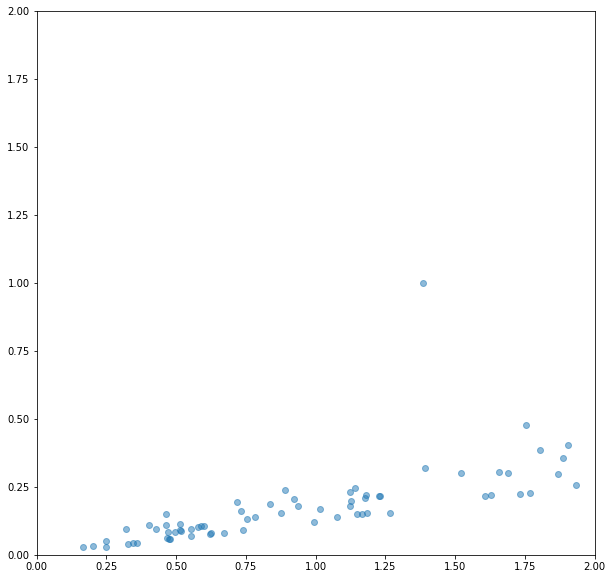

In [66]:
fig,ax = plt.subplots(1, figsize=(10, 10))
plt.scatter(ratios_1[0], ratios_2[0], alpha = 0.5)
plt.xlim([0,2])
plt.ylim([0,2])

(0.0, 2.0)

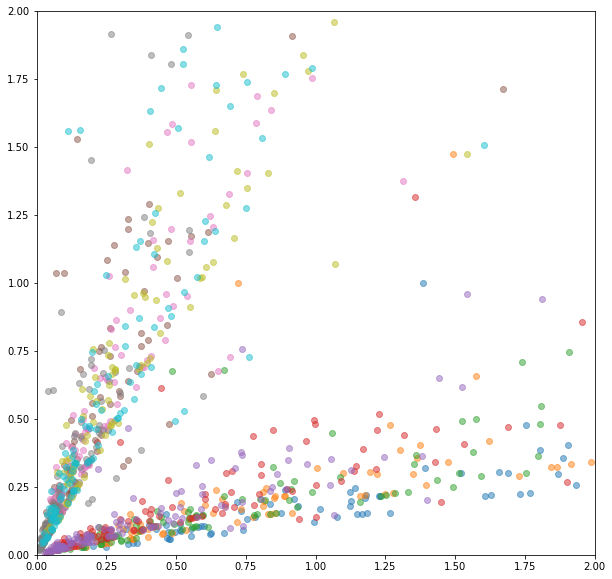

In [67]:
fig,ax = plt.subplots(1, figsize=(10, 10))
for r1, r2 in zip(ratios_1, ratios_2): 
#    fig,ax = plt.subplots(1, figsize=(10, 10))
    plt.scatter(r1, r2, alpha = 0.5)
plt.xlim([0,2])
plt.ylim([0,2])

(0.0, 2.0)

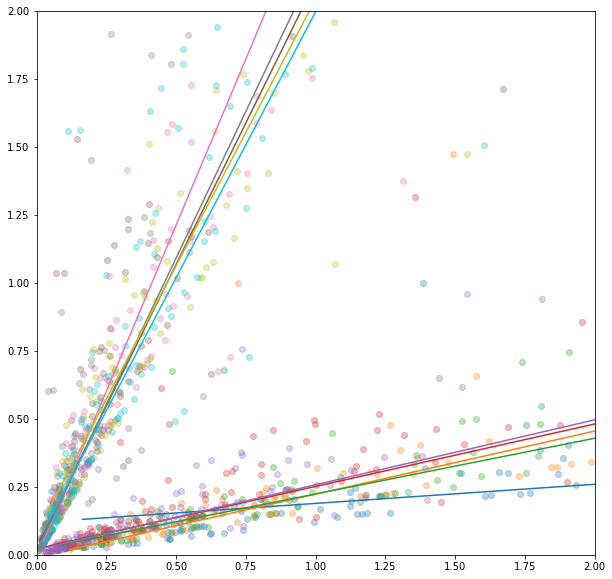

In [68]:
slopes1 = []
fig,ax = plt.subplots(1, figsize=(10, 10))
for r1, r2 in zip(ratios_1, ratios_2): 
#    fig,ax = plt.subplots(1, figsize=(10, 10))
    plt.scatter(r1, r2, alpha = 0.3)
for r1, r2 in zip(ratios_1, ratios_2): 
    
    model = RANSACRegressor(LinearRegression()).fit(np.array(r1).reshape(-1, 1), np.array(r2))
    slopes1.append(model.estimator_.coef_[0])
    x_fit = np.linspace(min(r1), max(r1), 100).reshape(-1, 1)
    y_fit = model.predict(x_fit)
    plt.plot(x_fit, y_fit)
plt.xlim([0,2])
plt.ylim([0,2])

In [69]:
#slopes

In [70]:
slopes1

[0.07031953537010784,
 0.231996264800405,
 0.20498270719858122,
 0.2296289785243849,
 0.23869762263786704,
 2.0826857740429325,
 2.444334714661698,
 2.1579629165517153,
 1.9631376584771263,
 1.9575471418585717]

In [71]:
print(len([c for c in cells_1 if c in normal_cells]))
print(len([c for c in cells_2 if c in normal_cells]))

0
319


In [72]:
counts_1 = all_data[cells_1].sum(axis = 1)
counts_2 = all_data[cells_2].sum(axis = 1)

In [73]:
new_data = all_data[cells_2]

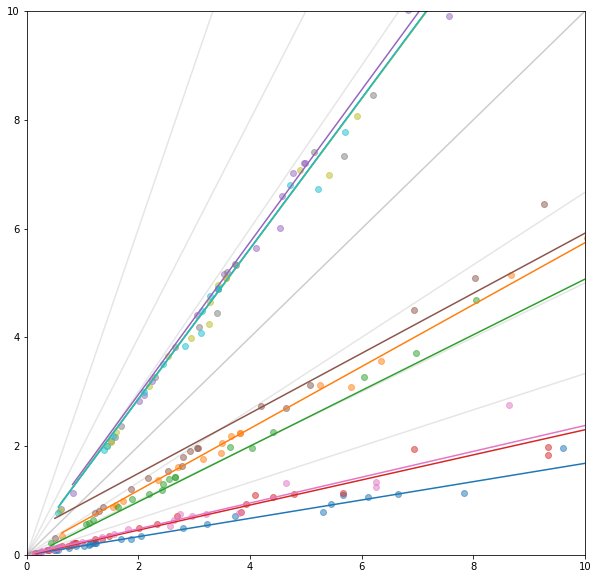

In [74]:
slopes, top_indices, bottom_indices, cells_1, cells_2 = ratio_of_ratios(all_data)

In [75]:
len([c for c in cells_1 if c in normal_cells]), len([c for c in cells_2 if c in normal_cells])


(0, 319)

In [76]:
new_data1 = all_data[cells_1]
new_data2 = all_data[cells_2]

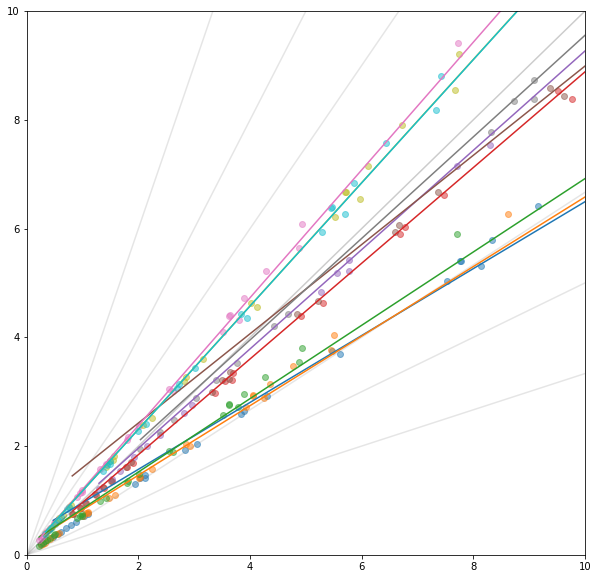

In [77]:
slopes1, top_indices1, bottom_indices1, cells_11, cells_12 = ratio_of_ratios(new_data1)

In [78]:
slopes1

[0.6150836162516635,
 0.6394318953985214,
 0.6743191987723477,
 0.8798462440087693,
 0.912989963786188,
 0.8204670705464279,
 1.1747821037689252,
 0.9336221978323107,
 1.1331383335894618,
 1.1329408888004417]

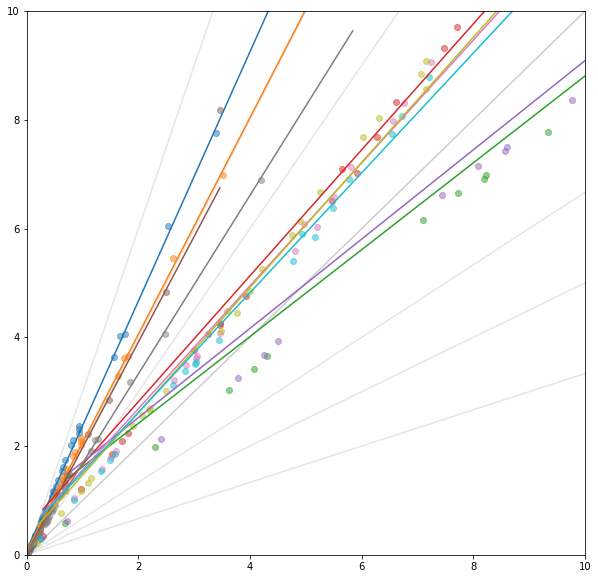

In [79]:
slopes2, top_indices2, bottom_indices2, cells_21, cells_22 = ratio_of_ratios(new_data2)

In [80]:
len(cells_21), len(cells_22)

(309, 28)

In [81]:
x = np.linspace(-10, 10, 500)
fractions = [(p, q) for p in range(-5, 6) for q in range(1, 6) if np.gcd(p, q) == 1 and not (p == 0)]


In [82]:
slopes2

[2.293085882810896,
 1.992202979031105,
 0.7983615248694133,
 1.1578880400334697,
 0.8205884729129421,
 1.9424554191802992,
 1.1296415565081315,
 1.6427077544747848,
 1.1501701008830907,
 1.1012858597736566]

In [83]:
new_data11 = all_data[cells_11]
new_data12 = all_data[cells_12]

In [84]:
len(cells_11), len(cells_12)

(361, 279)

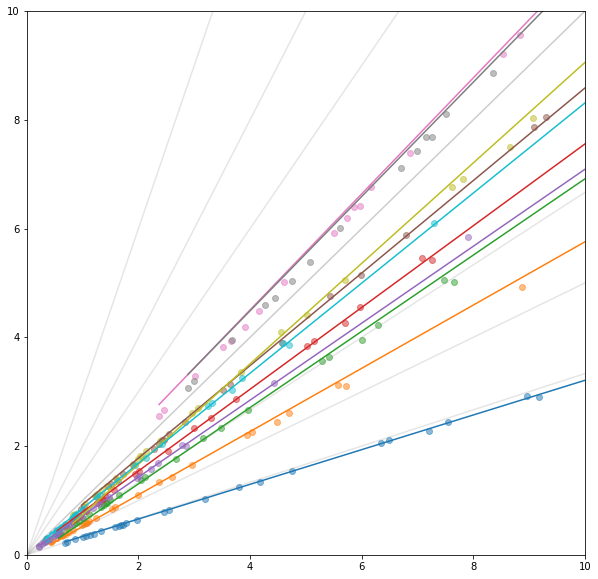

In [85]:
slopes11, top_indices11, bottom_indices11, cells_111, cells_112 = ratio_of_ratios(new_data11)

In [86]:
4/3

1.3333333333333333

In [87]:
slopes11

[0.3189256095144669,
 0.5816435183138483,
 0.7011305419622823,
 0.7518528401966817,
 0.7076894819120272,
 0.850747514118531,
 1.0671659102937945,
 1.0513457723715616,
 0.9239617825743077,
 0.8283372390949177]

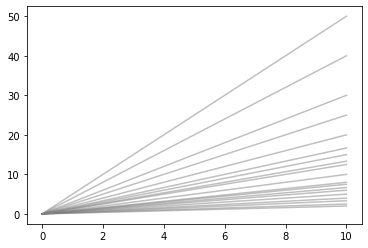

In [88]:
x = np.linspace(0, 10, 50)
fractions = [(p, q) for p in range(1, 6) for q in range(1, 6) if np.gcd(p, q) == 1 and not (p == 0)]
for p, q in fractions:
    slope = p / q
    y = slope * x
    plt.plot(x, y, alpha = 0.5, color = "grey")

(0.0, 10.0)

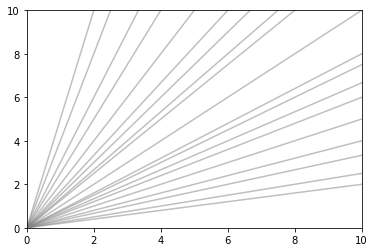

In [89]:
# Draw lines through the origin with slope = p/q
for p, q in fractions:
    slope = p / q
    y = slope * x
    plt.plot(x, y, alpha = 0.5, color = "grey")
plt.xlim([0,10])
plt.ylim([0,10])

In [90]:
fractions

[(1, 1),
 (1, 2),
 (1, 3),
 (1, 4),
 (1, 5),
 (2, 1),
 (2, 3),
 (2, 5),
 (3, 1),
 (3, 2),
 (3, 4),
 (3, 5),
 (4, 1),
 (4, 3),
 (4, 5),
 (5, 1),
 (5, 2),
 (5, 3),
 (5, 4)]

In [91]:
stop

NameError: name 'stop' is not defined

In [ ]:
logprob_NK_1, log_lik_1 = alg_on_single_seed(new_data)

In [ ]:
cluster21 =  np.where(np.array([x-y for x,y in logprob_NK_1])>0)[0]
cluster22 =  np.where(np.array([x-y for x,y in logprob_NK_1])<0)[0]

In [ ]:
cells_21 = [new_data.columns[i] for i in cluster21]
cells_22 = [new_data.columns[i] for i in cluster22]

In [ ]:
# counts_21 = new_data[cells_21].sum(axis = 1)
# counts_22 = new_data[cells_22].sum(axis = 1)

counts_21 = new_data[cells_21].sum(axis = 1)/data["lengths"]
counts_22 = new_data[cells_22].sum(axis = 1)/data["lengths"]

In [ ]:
counts_1 = all_data[cells_1].sum(axis = 1)/data["lengths"]
counts_2 = all_data[cells_2].sum(axis = 1)/data["lengths"]

# counts_1 = all_data[cells_1].sum(axis = 1)
# counts_2 = all_data[cells_2].sum(axis = 1)

# counts_1 = all_data[cells_1].sum(axis = 1)/data["normal_average"]
# counts_2 = all_data[cells_2].sum(axis = 1)/data["normal_average"]

In [ ]:
ratios_1 = []
ratios_2 = []
for pair in itertools.combinations(range(len(all_data)),2):
    i,j = pair
    ratios_1.append(counts_1[i]/counts_1[j])
    ratios_2.append(counts_2[i]/counts_2[j])

In [ ]:
ratios_21 = []
ratios_22 = []
for pair in itertools.combinations(range(len(all_data)),2):
    i,j = pair
    ratios_21.append(counts_21[i]/counts_21[j])
    ratios_22.append(counts_22[i]/counts_22[j])

In [ ]:
fig,ax = plt.subplots(1, figsize=(10, 10))
plt.scatter(ratios_1, ratios_2, alpha = 0.3)
plt.xlim([0,2])
plt.ylim([0,2])
fig,ax = plt.subplots(1, figsize=(10, 10))
plt.scatter(ratios_21, ratios_22, alpha = 0.3)
plt.xlim([0,2])
plt.ylim([0,2])

In [ ]:
new_data = all_data[cells_22]

In [ ]:
logprob_NK_1, log_lik_1 = alg_on_single_seed(new_data)

In [ ]:
cluster211 =  np.where(np.array([x-y for x,y in logprob_NK_1])>0)[0]
cluster212 =  np.where(np.array([x-y for x,y in logprob_NK_1])<0)[0]

In [ ]:
cells_211 = [new_data.columns[i] for i in cluster211]
cells_212 = [new_data.columns[i] for i in cluster212]

In [ ]:
# counts_211 = new_data[cells_211].sum(axis = 1)
# counts_212 = new_data[cells_212].sum(axis = 1)

counts_211 = new_data[cells_211].sum(axis = 1)/data["lengths"]
counts_212 = new_data[cells_212].sum(axis = 1)/data["lengths"]

In [ ]:
counts_1 = all_data[cells_1].sum(axis = 1)/data["lengths"]
counts_2 = all_data[cells_2].sum(axis = 1)/data["lengths"]

# counts_1 = all_data[cells_1].sum(axis = 1)
# counts_2 = all_data[cells_2].sum(axis = 1)

# counts_1 = all_data[cells_1].sum(axis = 1)/data["normal_average"]
# counts_2 = all_data[cells_2].sum(axis = 1)/data["normal_average"]

In [ ]:
ratios_1 = []
ratios_2 = []
for pair in itertools.combinations(range(len(all_data)),2):
    i,j = pair
    ratios_1.append(counts_1[i]/counts_1[j])
    ratios_2.append(counts_2[i]/counts_2[j])

In [ ]:
ratios_211 = []
ratios_212 = []
for pair in itertools.combinations(range(len(all_data)),2):
    i,j = pair
    ratios_211.append(counts_211[i]/counts_211[j])
    ratios_212.append(counts_212[i]/counts_212[j])

In [ ]:
fig,ax = plt.subplots(1, figsize=(10, 10))
plt.scatter(ratios_1, ratios_2, alpha = 0.3)
plt.xlim([0,2])
plt.ylim([0,2])
fig,ax = plt.subplots(1, figsize=(10, 10))
plt.scatter(ratios_211, ratios_212, alpha = 0.3)
plt.xlim([0,2])
plt.ylim([0,2])

In [ ]:
stop

In [ ]:
i,j = 0,1
print(counts_1[i]/counts_1[j])
print(counts_2[i]/counts_2[j])
t0 = time.time()
res = fisher_exact(np.array([[counts_1[i],counts_1[j]],[counts_2[i],counts_2[j]]]), alternative='two-sided')
t1 = time.time()

In [ ]:
res

In [ ]:
fisher_exact_1 = []
p_vals_1 = []
for pair in itertools.combinations(range(len(all_data)),2):
    i,j = pair
    ratios_1.append(counts_1[i]/counts_1[j])
    ratios_2.append(counts_2[i]/counts_2[j])
    
    res = fisher_exact(np.array([[counts_1[i],counts_1[j]],[counts_2[i],counts_2[j]]]), alternative='two-sided')
    fisher_exact_1.append(res)
    p_vals_1.append(res[1])

In [ ]:
logprob_NK_1, log_lik_1 = alg_on_single_seed(all_data[cells_2])

In [ ]:
cluster21 =  np.where(np.array([x-y for x,y in logprob_NK_1])>0)[0]
cluster22 =  np.where(np.array([x-y for x,y in logprob_NK_1])<0)[0]

In [ ]:
cells_21 = [all_data.columns[i] for i in cluster1]
cells_22 = [all_data.columns[i] for i in cluster2]

In [ ]:
counts_21 = all_data[cells_21].sum(axis = 1)
counts_22 = all_data[cells_22].sum(axis = 1)

In [ ]:
# sub_q = q_all_data[[q_all_data.columns[i] for i in cluster1]]
# new_sub = all_data[[all_data.columns[i] for i in cluster1]]

In [ ]:
ratios_21 = []
ratios_22 = []

In [ ]:
fisher_exact_2 = []
p_vals_2 = []
for pair in itertools.combinations(range(len(all_data)),2):
    i,j = pair
    ratios_21.append(counts_21[i]/counts_21[j])
    ratios_22.append(counts_22[i]/counts_22[j])
    
    res = fisher_exact(np.array([[counts_21[i],counts_21[j]],[counts_22[i],counts_22[j]]]), alternative='two-sided')
    fisher_exact_2.append(res)
    p_vals_2.append(res[1])

In [ ]:
poss_outputs_new, lik_new = alg_on_seeds(new_sub)

In [ ]:
logprob_NK = poss_outputs_new[np.argmax(lik_new)]



In [ ]:
# def Algorithm(all_data, count = 0, cut_off = 5000):
#     output = []
#     q_all_data = (all_data/all_data.sum(axis=0))
    
#     global new_order
#     new_order = [i for i in range(len(all_data.columns))]
    
#     global vlines
    
#     vlines = []
    
#     def binary_tree(all_data, q_all_data, before =[] , order = new_order, after=[],count = 0):
#         #print("instance")
        
#         global new_order
#         global vlines
        
#         if len(all_data.columns)<100:
#             return
        
#         poss_outputs, lik = alg_on_seeds(all_data)
        
#         logprob_NK = poss_outputs[np.argmax(lik)]
#         cluster1 =  np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
#         cluster2 =  np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
        
#         if len(cluster1)<50:
#             return
#         if len(cluster2)<50:
#             return
        
#         single_lik = calc_single(all_data, q_all_data)
        
#         if (max(lik)-single_lik)<=cut_off:
#             return
            
#         output.append([count,[all_data.columns[i] for i in cluster1], [all_data.columns[i] for i in cluster2],(max(lik)-single_lik)])        
        
#         sub_q = q_all_data[[q_all_data.columns[i] for i in cluster1]]
#         new_sub = all_data[[all_data.columns[i] for i in cluster1]]
        
#         order1 = [order[i] for i in cluster1]
#         order2 = [order[i] for i in cluster2]
        
        
#         print(before)
        
#         new_order = before+order1+order2+after
        
#         vlines.append([count, len(before+order1)])
#         count = count+1
        
#         binary_tree(new_sub, sub_q, before,order1, order2+after ,count)
        
#         sub_q = q_all_data[[q_all_data.columns[i] for i in cluster2]]
#         new_sub = all_data[[all_data.columns[i] for i in cluster2]]
        
#         binary_tree(new_sub, sub_q, new_order[:len(before+order1)],order2, after, count)
#         return
    
#     binary_tree(all_data, q_all_data, count = 0)
    
#     return output, new_order, vlines

In [ ]:
#output, new_order, vlines = Algorithm(all_data)

In [ ]:
# output_cell_list = [all_data.columns[i] for i in new_order]
# q_data = q_data[output_cell_list]

In [ ]:
# fig,ax = plt.subplots(1,figsize=(20, 10))
# h = ax.imshow(2*(q_data/q_data.mean(axis = 0).values), cmap = 'Reds',interpolation='nearest', aspect='auto', vmin=0, vmax=5)
# fig.colorbar(h)
# L = 1/len(vlines)
# lines = [l[1] for l in vlines]
# for l in vlines:
#     print(1 - l[0]*L)
#     plt.axvline(l[1], color = "black", alpha = 1-l[0]*L)

In [ ]:
# clusters = []
# current = 0
# for l in sorted(lines):
#     cl = []
#     for i in new_order[current:l]:
#         cl.append(all_data.columns[i])
#     clusters.append(cl)
#     current = l
# cl = []
# for i in new_order[current:]:
#     cl.append(all_data.columns[i])
# clusters.append(cl)

In [ ]:
#names_list = [name for name in seurat_clusters[1].unique() if name!="broken."+tumor+".txt"]

In [ ]:
# bar_lists = []
# for cl in clusters:
#     B = []
#     for name in names_list:
#         G = seurat_G.get_group(name)
#         n = len([name for name in G[0].values if name in cl])
#         B.append(n)
#     bar_lists.append(np.array(B))

In [ ]:
# prev = np.zeros(len(names_list))
# fig,ax = plt.subplots(1, figsize=(20, 10))
# for B in bar_lists:
#     plt.bar(names_list, B, bottom = prev)
#     prev = prev+B

In [ ]:
def int_diff(R,X0, X1):
    
    diff = lambda y : (y-round(y))**2
    out = 0
    
    for i in range(len(R)):
#         locs = loc_list[(loc_list["equi_bin"]<X[i+1]) & (loc_list["equi_bin"]>=X[i])]
#         out = out+diff(Y[i])*(len(locs))
        out = out + diff(R[i])*(X1[i]-X0[i])
    
    return out


def ploidy(R,X0,X1,m_range = [1.5,5.5]):
    mul = np.linspace(m_range[0],m_range[1],101)
    diff_list = []
    
    for m in mul:
        diff_list.append(int_diff(m*R,X0, X1))
    
    #a = np.argmin(diff_list)
    #plt.plot(mul,diff_list)
    return mul, diff_list

def ploidy_list(out):
    A = np.array(out[1])
    B = A[1:]-A[:-1]
    B0 = B[:-1]
    B1 = B[1:]
    I = np.where((B0<0) & (B1>0))[0] 
    return sorted(dict(zip([out[0][i+1] for i in I],[out[1][i+1] for i in I])).items(), key=lambda item: item[0])

    

In [ ]:
cells

In [ ]:
# def balanced_ploidy(cl):
#     balance_array = []
#     col = data[cl].sum(axis = 1)
#     normal_factor = data["normal_average"].values
#     Z = (((col/sum(col))*totlen)/(data["normal_average"])).values
#     for s in range(len(Z)):
#         hap = hap_grps.get_group(s)
#         sub_hap = hap[hap["cell"].isin(cl)]
#         hap_fractions_min = []
#         bin_list = sorted(sub_hap["bin"].unique())
#         for b in bin_list:
#             bin_info = sub_hap[sub_hap["bin"]==b]
#             h = bin_info["hap_count"].sum()/bin_info["Total"].sum()
#             hap_fractions_min.append(min(h, 1-h))
#         al = sum(hap_fractions_min)/len(hap_fractions_min)
#         balance_array.append(int((al>0.4)))

    
#     #print(Z)
#     out = ploidy(Z,X,Y)
#     #print(out)
#     all_pl = ploidy_list(out)
#     print(all_pl)
    
#     balance_pl = []
    
#     for p in all_pl:
#         pl = p[0]
#         b =(sum((np.array([int(round(z)%2==0) for z in (Z)*pl])*balance_array)*normal_factor)/sum(normal_factor*balance_array))
#         balance_pl.append(1-b)
#         #print(pl, b)
        
    
# #     best_pl = all_pl[np.argmax(balance_pl)][0]
#     print(balance_pl)
#     print(np.argsort(balance_pl))
#     for ind in np.argsort(balance_pl):
#         best_pl = all_pl[ind][0]
#         if sum([round(z)==0 for z in Z*best_pl])==0:
#             break
#         else:
#             print(Z*best_pl)

#     return best_pl

In [ ]:
def binary_search(a, L, start, end):
    if start==end:
        return start
    if a<=L[0]:
        return 0
    if a>=L[-1]:
        return len(L)-1
    mid = (end+start)//2
    
    if (a<L[mid]) and (a>=L[mid-1]):
        return mid
    elif a>=L[mid]:
        return binary_search(a, L, mid, end)
    else:
        return binary_search(a, L, start, mid)

In [ ]:
hap_count_df = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/per_cell_hap_count.txt", sep = "\t")
hap_count_df.head()
# bin_list = sorted(hap_count_df["bin"].unique())
# hap_type = dict()
# bin_list = sorted(hap_count_df["bin"].unique())
# for b in bin_list:
#     #print(b)
#     bin_info = hap_count_df[hap_count_df["bin"]==b]
#     h = bin_info["hap_count"].sum()/bin_info["Total"].sum()
#     hap_type[b] = int(h>=0.5)
# hap_grps = hap_count_df.groupby("seg")

In [ ]:
binning = pd.read_csv("/mnt/wigstore3/user/kendall/hg19.50mer/hg19.varbin.gc.content.2.5k.bowtie.k50.txt", sep='\t')
bin_loc_dict = dict(zip(binning.index, binning["bin.start.abspos"]))
hap_count_df["abspos"] = hap_count_df["bin"].apply(lambda x : bin_loc_dict[x])

In [ ]:
data.head()

In [ ]:
position_list = hap_count_df["abspos"].unique()
locations = bincounts["abend"].values
pos_seg = []
for p in position_list:
    pos_seg.append(binary_search(p,locations, 0, len(locations)))

In [ ]:
pos_seg_dict = dict(zip(position_list, pos_seg))

In [ ]:
hap_count_df["seg"] = hap_count_df["abspos"].apply(lambda x : pos_seg_dict[x])

In [ ]:
#hap_count_df.to_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/per_cell_hap_count_WGS_seg.txt", sep = "\t", index = None)

In [ ]:
bins_df = hap_count_df[["bin", "abspos", "seg"]].copy()
bins_df = bins_df.drop_duplicates()

In [ ]:
Normal_df = hap_count_df[hap_count_df["cell"].isin(normal_cells)]

In [ ]:
bin_groups = Normal_df.groupby("bin")
binstart = bins_df["bin"].values
ratio = []
for b in binstart:
    df = bin_groups.get_group(b)
    p = df["hap_count"].sum()/df["Total"].sum()
    ratio.append((min(p,1-p)))

In [ ]:
fig,ax = plt.subplots(1, figsize=(20, 10))
plt.scatter(Normal_df["abspos"].unique(), ratio)
plt.ylim([0, 0.5])
ax.set_xticklabels([]) 
plt.xlim(min(Normal_df["abspos"].unique()), max(Normal_df["abspos"].unique()))

In [ ]:
data["cum_length"] = data["normal_average"].cumsum()
X = [0]+list(data["cum_length"].values[:-1])
Y = data["cum_length"].values

In [ ]:
def balanced_ploidy(cl):
    T_df = hap_count_df[hap_count_df["cell"].isin(cl)]
    bin_groups = T_df.groupby("bin")
    
    binstart = bins_df["bin"].values
    ratio = []
    for b in binstart:
        df = bin_groups.get_group(b)
        p = df["hap_count"].sum()/df["Total"].sum()
        ratio.append((min(p,1-p)))
    
    bins_df["T_ratio"] = ratio
    
    seg_grps = bins_df.groupby("seg")
    T_al = []
    
    for s in bins_df["seg"].unique():
        segment = seg_grps.get_group(s)
        T_al.append(segment["T_ratio"].mean())
        
    T_al_balance = np.array([int(t>0.4) for t in T_al])
    col = data[cl].sum(axis = 1)
    
    normal_factor = data["normal_average"].values
    totlen = sum(normal_factor)
    
    Z = (((col/sum(col))*totlen)/(data["normal_average"])).values
    out = ploidy(Z,X,Y)
    all_pl = ploidy_list(out)
    fig,ax = plt.subplots(1, figsize=(20, 10))
    plt.plot(out[0], out[1])
    for l in all_pl:
        plt.axvline(l[0], color = "black")
    
    bl_ratio = []
#     print(Z)
#     print(T_al_balance)
    for p in all_pl:
        pl = p[0]
        CN = np.array([int(round(z)%2==0) for z in Z*pl])
        #print([round(z) for z in Z*pl])
        b =  sum((CN*T_al_balance)*normal_factor)/sum(T_al_balance*normal_factor)
        bl_ratio.append(b)
        print(pl, b)
    
    print(" ")
    best_pl = all_pl[np.argmax(bl_ratio)][0]
    
    
    return best_pl

In [ ]:
balanced_ploidy(normal_cells)

In [ ]:
col = data[normal_cells].sum(axis = 1)

In [ ]:
Z = (((col/sum(col))*totlen)/(data["normal_average"])).values
out = ploidy(Z,X,Y)
all_pl = ploidy_list(out)

In [ ]:
all_pl


In [ ]:
fig,ax = plt.subplots(1, figsize=(20, 10))
plt.plot(out[0], out[1])
for l in all_pl:
    plt.axvline(l[0], color = "black")

In [ ]:
out[0][np.argmin(out[1])]

In [ ]:
def Algorithm_with_ploidy(all_data,normal_average, count = 0, cut_off = 500):
    output = []
    q_all_data = (all_data/all_data.sum(axis=0))
    
    global reg_table
    reg_table = all_data.copy()
    reg_table["length"] = normal_average
    reg_table["cum_length"] = reg_table["length"].cumsum()
    
    global totlen
    totlen = sum(normal_average)
    
    global X
    X = [0]+list(reg_table["cum_length"].values[:-1])
    
    global Y
    Y = reg_table["cum_length"].values
        


    
    
    global new_order
    new_order = [i for i in range(len(all_data.columns))]
    
    global vlines
    vlines = []
    
    global CN_list
    CN_list = []
    
    def binary_tree(all_data, q_all_data, before =[] , order = new_order, after=[],count = 0, before_CN = [], after_CN = []):
        print("instance")
        
        global new_order
        global vlines
        global reg_table
        global totlen
        global X
        global Y
        global CN_list
        
        if len(all_data.columns)<100:
            return
        
        logprob_NK, lik = alg_on_single_seed(all_data)
        
        #cl = all_data.columns
        
        col = all_data.sum(axis = 1)
        
        Z = ((col/sum(col))*totlen)/(reg_table["length"])
        
        reg_table["temp"] = Z

#         out = ploidy(Z,X,Y)
#         all_pl = ploidy_list(out)
        
        #pl = []
        lens = np.array(Y)-np.array(X)
#         for i in range(len(all_pl)):
#         #print(sum((lens)*(Z*all_pl[i][0]).apply(lambda x : round(x)%2).values)/sum(lens)<0.3)
#             if (sum((lens)*(Z*all_pl[i][0]).apply(lambda x : round(x)%2).values)/sum(lens)<0.5):
#                 pl.append(all_pl[i][0])
        
        
        #pl = sorted(pl)
        
        
        cluster1 =  np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
        cluster2 =  np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
        
        print("split made")
        
        cl1,cl2 = [all_data.columns[i] for i in cluster1], [all_data.columns[i] for i in cluster2]
        
        if len(cl1)<50:
            return
        if len(cl2)<50:
            return

        col1 = reg_table[cl1].sum(axis = 1)
        col2 = reg_table[cl2].sum(axis = 1)
        
        Z1 = ((col1/sum(col1))*totlen)/(reg_table["length"])
        Z2 = ((col2/sum(col2))*totlen)/(reg_table["length"])
        #print(Z1==Z2)
        
        out1 = ploidy(Z1,X,Y)
        pl1 = out1[0][np.argmin(out1[1])]
        
#        all_pl1 = ploidy_list(out1)

#        pl1 = balanced_ploidy(cl1)
#         pl1 = []
#         for i in range(len(all_pl1)):
#         #print(sum((lens)*(Z*all_pl[i][0]).apply(lambda x : round(x)%2).values)/sum(lens)<0.3)
#             if (sum((lens)*(Z1*all_pl1[i][0]).apply(lambda x : round(x)%2).values)/sum(lens)<0.5):
#                 pl1.append(all_pl1[i][0])
        
        out2 = ploidy(Z2,X,Y)
        pl2 = out2[0][np.argmin(out2[1])]
        
#        all_pl2 = ploidy_list(out2)
#        pl2 = balanced_ploidy(cl2)
#         pl2 = []
#         for i in range(len(all_pl2)):
#         #print(sum((lens)*(Z*all_pl[i][0]).apply(lambda x : round(x)%2).values)/sum(lens)<0.3)
#             if (sum((lens)*(Z2*all_pl2[i][0]).apply(lambda x : round(x)%2).values)/sum(lens)<0.5):
#                 pl2.append(all_pl2[i][0])

        CN1 = (Z1*pl1).apply(lambda x : round(x))==(Z2*pl2).apply(lambda x : round(x))
        #CN2 = (Z1*pl1[1]).apply(lambda x : round(x))==(Z2*pl2[1]).apply(lambda x : round(x))
        
#         cn1 = (Z1*pl1[0]).apply(lambda x : round(x))
#         cn2 = (Z2*pl2[0]).apply(lambda x : round(x))
        cn1 = (Z1*pl1).apply(lambda x : round(x))
        cn2 = (Z2*pl2).apply(lambda x : round(x))
        
        print(sum(lens*CN1)/sum(lens))
              #, sum(lens*CN2)/sum(lens))
        print(len(cluster1), len(cluster2))
              
        if (sum(lens*CN1)/sum(lens)>=1):
              return
              
        if (sum(lens*CN1)/sum(lens)>0.95):
            return
        
#         if (sum(lens*CN1)/sum(lens)>=1) or (sum(lens*CN2)/sum(lens)>=1):
#             return
        
#         if (sum(lens*CN1)/sum(lens)>0.95) or (sum(lens*CN2)/sum(lens)>0.95):
#             return
            
        
        if len(cluster1)<50:
            return
        if len(cluster2)<50:
            return
        
        single_lik = calc_single(all_data, q_all_data)
        
        if (lik-single_lik)<=cut_off:
            return
            
        print("split determined")
        output.append([count,cl1,cl2,(lik-single_lik)])        
        
        sub_q = q_all_data[[q_all_data.columns[i] for i in cluster1]]
        new_sub = all_data[[all_data.columns[i] for i in cluster1]]
        
        order1 = [order[i] for i in cluster1]
        order2 = [order[i] for i in cluster2]
        
        
        #print(before)
        
        new_order = before+order1+order2+after
        CN_list = before_CN + [pl1] + [pl2] + after_CN
        
        vlines.append([count, len(before+order1)])
        count = count+1
        
        binary_tree(new_sub, sub_q, before,order1, order2+after ,count, before_CN, [pl2]+after_CN)
        
        sub_q = q_all_data[[q_all_data.columns[i] for i in cluster2]]
        new_sub = all_data[[all_data.columns[i] for i in cluster2]]
        
        CN_len = len(CN_list)
        after_len = len(after_CN)
        before_len = CN_len - after_len - 1
        
        binary_tree(new_sub, sub_q, new_order[:len(before+order1)],order2, after, count, CN_list[:before_len],after_CN)
        return
    
    binary_tree(all_data, q_all_data, count = 0)
    
    return output, new_order, vlines, CN_list

In [ ]:
table.head()

In [ ]:
normal_average = table["normal_average"].values

In [ ]:
all_data

In [ ]:
all_data = data[cells]

In [ ]:
output, new_order, vlines, CN_list = Algorithm_with_ploidy(all_data, normal_average)

In [ ]:
CN_list

In [ ]:
#output, new_order, vlines, CN_list = Algorithm_with_ploidy(all_data, normal_average)

In [ ]:
output_cell_list = [all_data.columns[i] for i in new_order]
q_data = q_data[output_cell_list]

In [ ]:
break_points.head()

In [ ]:
data["len_factor"] = data[normal_cells].sum(axis = 1)/len(normal_cells)

In [ ]:
data

In [ ]:
h_lines = data[data["chrom"]!=data.shift(-1)["chrom"]].index.values
chrom_mid = (np.array([0]+list(h_lines[:-1]))+h_lines)/2
chrom_names = ["chr"+str(i) for i in range(1,23)]+["chrX"]

In [ ]:
fig,ax = plt.subplots(1,figsize=(20, 10))
h = ax.imshow(2*(q_data/q_data.mean(axis = 0).values).values.astype(float), cmap = 'RdBu',interpolation='nearest', aspect='auto', vmin=0, vmax=4)
#fig.colorbar(h)
cbar = fig.colorbar(h)
L = 1/len(vlines)
lines = [l[1] for l in vlines]
ax.set_xticks([])
ax.set_yticks(list(chrom_mid[:18])+[chrom_mid[19],chrom_mid[-1]])
ax.set_yticklabels(chrom_names[:18]+[chrom_names[19], chrom_names[-1]])

plt.rc('xtick', labelsize=20) 
plt.rc('ytick', labelsize=20)
for l in vlines:
    print(1 - l[0]*L)
    plt.axvline(l[1], color = "black", alpha = 1-l[0]*L)
for l in h_lines[:-1]:
    plt.axhline(l, color = "black", linewidth=0.5)

cbar.set_label("Copy number in bin", fontsize = 20)

plt.title("Tumor and normal clones in single cells", fontsize = 20)

In [ ]:
lines = sorted([l[1] for l in vlines])+[np.inf]

In [ ]:
pl_list = CN_list

In [ ]:
l = lines[0]
c = pl_list[0]
j = 0
lines, CN_list


In [ ]:
cell_ploidies = []
for i in range(len(q_data.columns)):
    if i<l:
        cell_ploidies.append(c)
    if i == l: 
        j = j+1
        l = lines[j]
        c = pl_list[j]
        cell_ploidies.append(c)


In [ ]:
q_data_quantal_CN = pd.DataFrame()

In [ ]:
name = q_data.columns[0]
col = q_data[name]


In [ ]:
count = 0
for name in q_data.columns:
    col = q_data[name]
    q_data_quantal_CN[name] = ((col/col.mean())*cell_ploidies[count]).apply(round)
    count = count+1

In [ ]:
len_image_adjust = (data["len_factor"]//10).values
len_adjusted = []
for i in range(len(q_data.values)):
    l = q_data.values[i]
    for ind in range(int(len_image_adjust[i])):
        len_adjusted.append(list(l))
len_adjusted = np.array(len_adjusted)

In [ ]:
data["len_image"] = (data["len_factor"]//10).values

In [ ]:
data["len_image_cumsum"] = data["len_image"].cumsum()

In [ ]:
h_lines = data[data["chrom"]!=data.shift(-1)["chrom"]]["len_image_cumsum"].values
chrom_mid = (np.array([0]+list(h_lines[:-1]))+h_lines)/2

In [ ]:
fig,ax = plt.subplots(1,figsize=(20, 10))
h = ax.imshow(2*(len_adjusted/len_adjusted.mean(axis = 0)).astype(float), cmap = 'RdBu',interpolation='nearest', aspect='auto', vmin=0, vmax=4)


cbar = fig.colorbar(h)
L = 1/len(vlines)
lines = [l[1] for l in vlines]
ax.set_xticks([])
ax.set_yticks(list(chrom_mid[:18])+[chrom_mid[19],chrom_mid[-1]])
ax.set_yticklabels(chrom_names[:18]+[chrom_names[19], chrom_names[-1]])

plt.rc('xtick', labelsize=18) 
plt.rc('ytick', labelsize=18)
for l in vlines:
    print(1 - l[0]*L)
    plt.axvline(l[1], color = "black", alpha = 1-l[0]*L)
for l in h_lines[:-1]:
    plt.axhline(l, color = "black", linewidth=0.5)

cbar.set_label("Copy number in bin", fontsize = 20)
plt.title("Tumor and normal populations in single cells", fontsize = 20)

In [ ]:
len_image_adjust = (data["len_factor"]//10).values
len_adjusted_quantal = []
for i in range(len(q_data_quantal_CN.values)):
    l = q_data_quantal_CN.values[i]
    for ind in range(int(len_image_adjust[i])):
        len_adjusted_quantal.append(list(l))
len_adjusted_quantal = np.array(len_adjusted_quantal)

In [ ]:
fig,ax = plt.subplots(1,figsize=(20, 10))
h = ax.imshow(len_adjusted_quantal, cmap = 'RdBu',interpolation='nearest', aspect='auto', vmin = 0, vmax = 6)
#fig.colorbar(h)
cbar = fig.colorbar(h)
L = 1/len(vlines)
lines = [l[1] for l in vlines]
ax.set_xticks([])
ax.set_yticks(list(chrom_mid[:18])+[chrom_mid[19],chrom_mid[-1]])
ax.set_yticklabels(chrom_names[:18]+[chrom_names[19], chrom_names[-1]])

plt.rc('xtick', labelsize=20) 
plt.rc('ytick', labelsize=20)
for l in vlines:
    print(l[1],1 - l[0]*L)
    plt.axvline(l[1], color = "black")
for l in h_lines[:-1]:
    plt.axhline(l, color = "black", linewidth=0.5)

cbar.set_label("Copy number in bin", fontsize = 20)

plt.title("Tumor and normal clones in single cells", fontsize = 20)

In [ ]:
clusters = []
current = 0
c = 1
row_list = []
for l in sorted(lines):
    cl = []
    for i in new_order[current:l]:
        cl.append(all_data.columns[i])
        row_list.append({"cell":all_data.columns[i], "cluster" : c})
    clusters.append(cl)
    c = c+1
    current = l
cl = []
for i in new_order[current:]:
    cl.append(all_data.columns[i])
    row_list.append({"cell":all_data.columns[i], "cluster" : c})
clusters.append(cl)

In [ ]:
mult_KV = []
for cl in clusters:
    mult_KV.append(((all_data[cl].sum(axis = 1))/(all_data[cl].sum(axis = 1)).sum()).values)

mult_KV = np.array(mult_KV)
member_dict = dict()
log_member_dict = dict()

In [ ]:
clusters1 = [[] for cl in clusters]
membership = []
l_membership = []
membership_arg = []
excep = []
excep_M = []

for c in output_cell_list:
    L = np.dot(np.log(mult_KV),all_data[c].values)
    lM = L - logsumexp(L)
    M = np.exp(lM)
    member_dict[c] = M
    log_member_dict[c] = lM
    l_membership.append(lM)
    membership.append(M)
    membership_arg.append(np.argmax(M))
    clusters1[np.argmax(M)].append(c)
    if max(M)<0.9:
        excep.append(c)
        excep_M.append(M)

In [ ]:
normal_read_mean = all_data[normal_cells].sum().mean()

In [ ]:
5

In [ ]:
cluster_count_means = []
for cl in clusters1:
    cluster_count_means.append(all_data[cl].sum().mean())
    print(all_data[cl].sum().mean()/normal_read_mean)

In [ ]:
new_output_list = []
vlines = []
l = 0
cell_ploidies = []
cluster_ploidies = []
for cl in clusters1:
    vlines.append(l)
    new_output_list = new_output_list+cl
    l = l+len(cl)
    pl = balanced_ploidy(cl)
    cell_ploidies = cell_ploidies+[pl for c in cl]
    cluster_ploidies.append(pl)
vlines.append(l)


In [ ]:
def balanced_ploidy_read_counts(cl, all_data, normal_read_mean):
    T_df = hap_count_df[hap_count_df["cell"].isin(cl)]
    bin_groups = T_df.groupby("bin")
    
    binstart = bins_df["bin"].values
    ratio = []
    for b in binstart:
        df = bin_groups.get_group(b)
        p = df["hap_count"].sum()/df["Total"].sum()
        ratio.append((min(p,1-p)))
    
    bins_df["T_ratio"] = ratio
    
    seg_grps = bins_df.groupby("seg")
    T_al = []
    
    for s in bins_df["seg"].unique():
        segment = seg_grps.get_group(s)
        T_al.append(segment["T_ratio"].mean())
        
    T_al_balance = np.array([int(t>0.4) for t in T_al])
    col = all_data[cl].sum(axis = 1)
    
    normal_factor = data["normal_average"].values
    totlen = sum(normal_factor)
    
    Z = (((col/sum(col))*totlen)/(data["normal_average"])).values
    out = ploidy(Z,X,Y)
    all_pl = ploidy_list(out)
    fig,ax = plt.subplots(1, figsize=(20, 10))
    plt.plot(out[0], out[1])
    for l in all_pl:
        plt.axvline(l[0], color = "black")
    
    bl_ratio = []
#     print(Z)
#     print(T_al_balance)
    for p in all_pl:
        pl = p[0]
        CN = np.array([int(round(z)%2==0) for z in Z*pl])
        #print([round(z) for z in Z*pl])
        b =  sum((CN*T_al_balance)*normal_factor)/sum(T_al_balance*normal_factor)
        bl_ratio.append(b)
        print(pl, b)
    
    pl_read_count = 2*(all_data[cl].sum().mean()/normal_read_mean)
    
    print(" ")
    
    
    sorted_indices = sorted(range(len(bl_ratio)), key=lambda x: bl_ratio[x], reverse = True)
    
    sorted_indices = [i for i in sorted_indices if bl_ratio[i]>0.7]
    
    
    pos_pl = [all_pl[s][0] for s in sorted_indices]
    
    try:
        best_pl = min(pos_pl, key=lambda x: abs(x - pl_read_count))
    except:
        s = np.argmax(bl_ratio)
        best_pl = all_pl[s][0]
    
    print(pl_read_count, pos_pl)
    
    print(" ")
    
    
    #best_pl = all_pl[np.argmax(bl_ratio)][0]
    
    
    return best_pl

In [ ]:
new_output_list = []
vlines = []
l = 0
cell_ploidies = []
cluster_ploidies = []
CN_list = []
for cl in clusters1:
    vlines.append(l)
    new_output_list = new_output_list+cl
    l = l+len(cl)
    pl = balanced_ploidy_read_counts(cl, all_data, normal_read_mean)
    cell_ploidies = cell_ploidies+[pl for c in cl]
    cluster_ploidies.append(pl)
    
    col = all_data[cl].sum(axis = 1)
    Z = (((col/sum(col))*totlen)/(data["normal_average"])).values
    CN = np.array([round(z) for z in Z*pl])
    
    CN_list.append(CN)
    
vlines.append(l)

In [ ]:
cluster_ploidies

In [ ]:

my_list = [5, 2, 9, 1, 4]

# Get the indices of the sorted list
sorted_indices = sorted(range(len(my_list)), key=lambda x: my_list[x], reverse=True)

print(sorted_indices)

In [ ]:
q_data = q_data[new_output_list]
q_data_quantal_CN = pd.DataFrame()
name = q_data.columns[0]
col = q_data[name]


In [ ]:
count = 0
for name in q_data.columns:
    col = q_data[name]
    q_data_quantal_CN[name] = ((col/col.mean())*cell_ploidies[count]).apply(round)
    count = count+1

In [ ]:
len_image_adjust = (data["len_factor"]//10).values
len_adjusted = []
for i in range(len(q_data.values)):
    l = q_data.values[i]
    for ind in range(int(len_image_adjust[i])):
        len_adjusted.append(list(l))
len_adjusted = np.array(len_adjusted)

In [ ]:
data["len_image"] = (data["len_factor"]//10).values

In [ ]:
data["len_image_cumsum"] = data["len_image"].cumsum()

In [ ]:
h_lines = data[data["chrom"]!=data.shift(-1)["chrom"]]["len_image_cumsum"].values
chrom_mid = (np.array([0]+list(h_lines[:-1]))+h_lines)/2

In [ ]:
fig,ax = plt.subplots(1,figsize=(20, 10))
h = ax.imshow(2*(len_adjusted/len_adjusted.mean(axis = 0)).astype(float), cmap = 'RdBu',interpolation='nearest', aspect='auto', vmin=0, vmax=4)


cbar = fig.colorbar(h)
L = 1/len(vlines)
#lines = [l[1] for l in vlines]
ax.set_xticks([])
ax.set_yticks(list(chrom_mid[:18])+[chrom_mid[19],chrom_mid[-1]])
ax.set_yticklabels(chrom_names[:18]+[chrom_names[19], chrom_names[-1]])

plt.rc('xtick', labelsize=18) 
plt.rc('ytick', labelsize=18)
for l in vlines:
    plt.axvline(l, color = "black")
for l in h_lines[:-1]:
    plt.axhline(l, color = "black", linewidth=0.5)

cbar.set_label("Copy number in bin", fontsize = 20)
plt.title("Tumor and normal populations in single cells", fontsize = 20)
plt.xlim([vlines[0], vlines[-1]])

In [ ]:
len_image_adjust = (data["len_factor"]//10).values
len_adjusted_quantal = []
for i in range(len(q_data_quantal_CN.values)):
    l = q_data_quantal_CN.values[i]
    for ind in range(int(len_image_adjust[i])):
        len_adjusted_quantal.append(list(l))
len_adjusted_quantal = np.array(len_adjusted_quantal)

In [ ]:
# Create a custom diverging colormap (red -> white -> blue)
custom_cmap = LinearSegmentedColormap.from_list(
    "red_white_blue", ["red", "white", "blue"]
)

# Define normalization: red at 0, white at 2, blue at 6
norm = TwoSlopeNorm(vmin=0, vcenter=2, vmax=6)

In [ ]:
fig,ax = plt.subplots(1,figsize=(20, 10))
h = ax.imshow(len_adjusted_quantal, cmap = "RdBu",norm=norm,interpolation='nearest', aspect='auto', vmin = 0, vmax = 6)
#fig.colorbar(h)
cbar = fig.colorbar(h)
L = 1/len(vlines)
#lines = [l[1] for l in vlines]
ax.set_xticks([])
ax.set_yticks(list(chrom_mid[:18])+[chrom_mid[19],chrom_mid[-1]])
ax.set_yticklabels(chrom_names[:18]+[chrom_names[19], chrom_names[-1]])

plt.rc('xtick', labelsize=20) 
plt.rc('ytick', labelsize=20)
for l in vlines:
    #print(l[1],1 - l[0]*L)
    plt.axvline(l, color = "black")
for l in h_lines[:-1]:
    plt.axhline(l, color = "black", linewidth=0.5)

cbar.set_label("Copy number in bin", fontsize = 20)

plt.title("Tumor and normal clones in single cells", fontsize = 20)
plt.xlim([vlines[0], vlines[-1]])

In [ ]:
scope = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/t57/cell_names_t57_SCOPE.txt", header = None)[0].values

In [ ]:
scope

In [ ]:
set(cell_ploidies)

In [ ]:
T1 = clusters1[2]

In [ ]:
pl = 2.8
temp_df = pd.DataFrame()
for name in T1:
    col = q_data[name]
    temp_df[name] = ((col/col.mean())*pl).apply(round)

In [ ]:
len_image_adjust = (data["len_factor"]//10).values
len_adjusted_quantal = []
for i in range(len(temp_df[T1].values)):
    l = temp_df[T1].values[i]
    for ind in range(int(len_image_adjust[i])):
        len_adjusted_quantal.append(list(l))
len_adjusted_quantal = np.array(len_adjusted_quantal)

In [ ]:
# Create a custom diverging colormap (red -> white -> blue)
custom_cmap = LinearSegmentedColormap.from_list(
    "red_white_blue", ["red", "white", "blue"]
)

# Define normalization: red at 0, white at 2, blue at 6
norm = TwoSlopeNorm(vmin=0, vcenter=2, vmax=6)

In [ ]:
fig,ax = plt.subplots(1,figsize=(20, 10))
h = ax.imshow(len_adjusted_quantal, cmap = "RdBu",norm=norm,interpolation='nearest', aspect='auto', vmin = 0, vmax = 6)
#fig.colorbar(h)
cbar = fig.colorbar(h)
L = 1/len(vlines)
#lines = [l[1] for l in vlines]
ax.set_xticks([])
ax.set_yticks(list(chrom_mid[:18])+[chrom_mid[19],chrom_mid[-1]])
ax.set_yticklabels(chrom_names[:18]+[chrom_names[19], chrom_names[-1]])

plt.rc('xtick', labelsize=20) 
plt.rc('ytick', labelsize=20)
# for l in vlines:
#     #print(l[1],1 - l[0]*L)
#     plt.axvline(l, color = "black")
for l in h_lines[:-1]:
    plt.axhline(l, color = "black", linewidth=0.5)

cbar.set_label("Copy number in bin", fontsize = 20)

plt.title("Tumor profile with ploidy "+str(pl), fontsize = 20)
#plt.xlim([vlines[0], vlines[-1]])

In [ ]:
T2 = clusters1[3]

In [ ]:
pl = 3.45
temp_df = pd.DataFrame()
for name in T2:
    col = q_data[name]
    temp_df[name] = ((col/col.mean())*pl).apply(round)

In [ ]:
len_image_adjust = (data["len_factor"]//10).values
len_adjusted_quantal = []
for i in range(len(temp_df[T2].values)):
    l = temp_df[T2].values[i]
    for ind in range(int(len_image_adjust[i])):
        len_adjusted_quantal.append(list(l))
len_adjusted_quantal = np.array(len_adjusted_quantal)

In [ ]:
# Create a custom diverging colormap (red -> white -> blue)
custom_cmap = LinearSegmentedColormap.from_list(
    "red_white_blue", ["red", "white", "blue"]
)

# Define normalization: red at 0, white at 2, blue at 6
norm = TwoSlopeNorm(vmin=0, vcenter=2, vmax=6)

In [ ]:
fig,ax = plt.subplots(1,figsize=(20, 10))
h = ax.imshow(len_adjusted_quantal, cmap = "RdBu",norm=norm,interpolation='nearest', aspect='auto', vmin = 0, vmax = 6)
#fig.colorbar(h)
cbar = fig.colorbar(h)
L = 1/len(vlines)
#lines = [l[1] for l in vlines]
ax.set_xticks([])
ax.set_yticks(list(chrom_mid[:18])+[chrom_mid[19],chrom_mid[-1]])
ax.set_yticklabels(chrom_names[:18]+[chrom_names[19], chrom_names[-1]])

plt.rc('xtick', labelsize=20) 
plt.rc('ytick', labelsize=20)
# for l in vlines:
#     #print(l[1],1 - l[0]*L)
#     plt.axvline(l, color = "black")
for l in h_lines[:-1]:
    plt.axhline(l, color = "black", linewidth=0.5)

cbar.set_label("Copy number in bin", fontsize = 20)

plt.title("Tumor profile with ploidy "+str(pl), fontsize = 20)
#plt.xlim([vlines[0], vlines[-1]])

In [ ]:
df_list = []
normal_cluster_count = 1
tumor_cluster_count = 1
for cl in clusters1:
    df = pd.DataFrame()
    df["cells"] = cl
    print(len([c for c in cl if c in normal_cells])/len(cl))
    if (len([c for c in cl if c in normal_cells])/len(cl))>0.6:
        df["clusters"] = "Normal_"+str(normal_cluster_count)
        normal_cluster_count = normal_cluster_count+1
        
    else:
        df["clusters"] = "Tumor_"+str(tumor_cluster_count)
        tumor_cluster_count = tumor_cluster_count+1
    df_list.append(df)
multinomial_clusters = pd.concat(df_list)

In [ ]:
num_normal_cells =len(multinomial_clusters[multinomial_clusters["clusters"] == "Normal_1"])

In [ ]:
multinomial_clusters[multinomial_clusters["clusters"] == "Normal_1"]["cells"].values

In [ ]:
len(len_adjusted_quantal)

In [ ]:
len(cells)

In [ ]:
possible_chrom_loss_normals = []
for c in multinomial_clusters[multinomial_clusters["clusters"] == "Normal_1"]["cells"].values:
    counter = 0
    for val in q_data_quantal_CN[c].values:
        if val==0:
            counter+=1
    if counter>1:
        possible_chrom_loss_normals.append(c)

In [ ]:
h_lines

In [ ]:
len(possible_chrom_loss_normals)

In [ ]:
len_image_adjust = (data["len_factor"]//10).values
len_adjusted = []
for i in range(len(q_data[possible_chrom_loss_normals].values)):
    l = q_data[possible_chrom_loss_normals[:20]].values[i]
    for ind in range(int(len_image_adjust[i])):
        len_adjusted.append(list(l))
len_adjusted = np.array(len_adjusted)

In [ ]:
data["len_image"] = (data["len_factor"]//10).values

In [ ]:
data["len_image_cumsum"] = data["len_image"].cumsum()

In [ ]:
h_lines = data[data["chrom"]!=data.shift(-1)["chrom"]]["len_image_cumsum"].values
chrom_mid = (np.array([0]+list(h_lines[:-1]))+h_lines)/2

In [ ]:
fig,ax = plt.subplots(1,figsize=(20, 10))
h = ax.imshow(2*(len_adjusted/len_adjusted.mean(axis = 0)).astype(float), cmap = 'RdBu',interpolation='nearest', aspect='auto', vmin=0, vmax=4)


cbar = fig.colorbar(h)
L = 1/len(vlines)
#lines = [l[1] for l in vlines]
ax.set_xticks([])
ax.set_yticks(list(chrom_mid[:18])+[chrom_mid[19],chrom_mid[-1]])
ax.set_yticklabels(chrom_names[:18]+[chrom_names[19], chrom_names[-1]])

plt.rc('xtick', labelsize=18) 
plt.rc('ytick', labelsize=18)
# for l in vlines:
#     plt.axvline(l, color = "black")
for l in h_lines[:-1]:
    plt.axhline(l, color = "black", linewidth=0.5)

cbar.set_label("Copy number in bin", fontsize = 20)
plt.title("Tumor and normal populations in single cells", fontsize = 20)
#plt.xlim([vlines[0], vlines[-1]])

In [ ]:
len_image_adjust = (data["len_factor"]//10).values
len_adjusted_quantal = []
for i in range(len(q_data_quantal_CN[possible_chrom_loss_normals].values)):
    l = q_data_quantal_CN[possible_chrom_loss_normals[:20]].values[i]
    for ind in range(int(len_image_adjust[i])):
        len_adjusted_quantal.append(list(l))
len_adjusted_quantal = np.array(len_adjusted_quantal)

In [ ]:
# Create a custom diverging colormap (red -> white -> blue)
custom_cmap = LinearSegmentedColormap.from_list(
    "red_white_blue", ["red", "white", "blue"]
)

# Define normalization: red at 0, white at 2, blue at 6
norm = TwoSlopeNorm(vmin=0, vcenter=2, vmax=6)

In [ ]:
fig,ax = plt.subplots(1,figsize=(20, 10))
h = ax.imshow(len_adjusted_quantal, cmap = "RdBu",norm=norm,interpolation='nearest', aspect='auto', vmin = 0, vmax = 6)
#fig.colorbar(h)
cbar = fig.colorbar(h)
L = 1/len(vlines)
#lines = [l[1] for l in vlines]
ax.set_xticks([])
ax.set_yticks(list(chrom_mid[:18])+[chrom_mid[19],chrom_mid[-1]])
ax.set_yticklabels(chrom_names[:18]+[chrom_names[19], chrom_names[-1]])

plt.rc('xtick', labelsize=20) 
plt.rc('ytick', labelsize=20)
# for l in vlines:
#     #print(l[1],1 - l[0]*L)
#     plt.axvline(l, color = "black")
for l in h_lines[:-1]:
    plt.axhline(l, color = "black", linewidth=0.5)

cbar.set_label("Copy number in bin", fontsize = 20)

plt.title("Normal cells", fontsize = 20)
#plt.xlim([vlines[0], vlines[-1]])

In [ ]:
q_data_quantal_CN[possible_chrom_loss_normals]

In [ ]:
normal_first = [list(l[-num_normal_cells:])+list(l[:-num_normal_cells]) for l in len_adjusted_quantal]

In [ ]:
vlines

In [ ]:
new_vlines = [0, num_normal_cells]+[v+num_normal_cells for v in vlines[1:-1]]

In [ ]:
# fig,ax = plt.subplots(1,figsize=(20, 10))
# h = ax.imshow(normal_first, cmap = "RdBu",norm=norm,interpolation='nearest', aspect='auto', vmin = 0, vmax = 6)
# #fig.colorbar(h)
# cbar = fig.colorbar(h)
# L = 1/len(new_vlines)
# #lines = [l[1] for l in vlines]
# ax.set_xticks([])
# ax.set_yticks(list(chrom_mid[:18])+[chrom_mid[19],chrom_mid[-1]])
# ax.set_yticklabels(chrom_names[:18]+[chrom_names[19], chrom_names[-1]])

# plt.rc('xtick', labelsize=20) 
# plt.rc('ytick', labelsize=20)
# for l in new_vlines:
#     #print(l[1],1 - l[0]*L)
#     plt.axvline(l, color = "black")
# for l in h_lines[:-1]:
#     plt.axhline(l, color = "black", linewidth=0.5)

# cbar.set_label("Copy number in bin", fontsize = 20)

# plt.title("Tumor and normal clones without the broken cells", fontsize = 20)
# plt.xlim([vlines[0], vlines[-1]])

In [ ]:
#multinomial_clusters.to_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/"+tumor+".multinomial_clusters.txt", sep = "\t", index = None)

In [ ]:
membership = []
l_membership = []
for c in new_output_list:
    M = member_dict[c]
    lM = log_member_dict[c]
    l_membership.append(lM)
    membership.append(M)

In [ ]:
fig,ax = plt.subplots(1,figsize=(20, 10))
ax.set_yticks([0,1,2,3,4])
ax.set_yticklabels(["T1","T2", "T3","T4","Normal"])
ax.imshow(np.transpose(l_membership),interpolation='nearest', aspect='auto')
plt.title("Log-membership probability of a nucleus belonging to a sub-clone",fontsize = 20)

In [ ]:
fig,ax = plt.subplots(1,figsize=(20, 10))
ax.set_yticks([0,1,2,3,4])
ax.set_yticklabels(["T1","T2", "T3","T4","Normal"])
ax.imshow(np.transpose(membership),interpolation='nearest', aspect='auto')
plt.title("Membership probability of a nucleus belonging to a sub-clone",fontsize = 20)

In [ ]:
hap_count_df = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/per_cell_hap_count.txt", sep = "\t")

In [ ]:
stop

In [ ]:
#read_count_df = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/"+tumor+".read_counts.txt", sep = "\t", header = None) 

In [ ]:
#pd.DataFrame(row_list).to_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/multinomial_clusters_no_adjust.txt", sep = "\t", index = None)

In [ ]:
read_count_df.head()

In [ ]:
read_count_dict = dict(zip(read_count_df[0].values, read_count_df[1].values))

In [ ]:
normals = clusters[-1]

In [ ]:
fig,ax = plt.subplots(1, figsize=(20, 10))
counts = read_count_df[read_count_df[0].isin(normals)][1].values
plt.hist(counts, bins = 20, alpha = 0.4, label = "Normal")

# plt.show()
# fig,ax = plt.subplots(1, figsize=(20, 10))
counts = read_count_df[~read_count_df[0].isin(normals)][1].values
plt.hist(counts, bins = 20, alpha = 0.4, label = "Tumor")
plt.xlabel("Unique read counts",fontsize = 20)
plt.ylabel("Number of nuclei",fontsize = 20)
plt.legend(fontsize = 20)

In [ ]:
avg_counts = []
for cl in clusters:
    fig,ax = plt.subplots(1, figsize=(20, 10))
    counts = read_count_df[read_count_df[0].isin(cl)][1].values
    avg_counts.append(sum(counts)/len(counts))
    plt.hist(counts, alpha = 0.4)
    plt.show()

In [ ]:
normal_avg = avg_counts[-1]
normal_ploidy = CN_list[-1]

In [ ]:
for a in avg_counts:
    print((a/normal_avg)*normal_ploidy)

In [ ]:
bar_lists = []
for cl in clusters:
    B = []
    for name in names_list:
        G = seurat_G.get_group(name)
        n = len([name for name in G[0].values if name in cl])
        B.append(n)
    bar_lists.append(np.array(B))

In [ ]:
#names_list = ["TumorA", "TumorB", "Normal"]

In [ ]:
prev = np.zeros(len(names_list))
fig,ax = plt.subplots(1, figsize=(20, 10))
for B in bar_lists:
    plt.bar(names_list, B, bottom = prev)
    prev = prev+B

In [ ]:
mult_KV = []
for cl in clusters:
    mult_KV.append(((all_data[cl].sum(axis = 1))/(all_data[cl].sum(axis = 1)).sum()).values)

In [ ]:
mult_KV = np.array(mult_KV)

In [ ]:
member_dict = dict()
log_member_dict = dict()

In [ ]:
clusters1 = [[] for cl in clusters]
membership = []
l_membership = []
membership_arg = []
excep = []
excep_M = []

for c in output_cell_list:
    L = np.dot(np.log(mult_KV),all_data[c].values)
    lM = L - logsumexp(L)
    M = np.exp(lM)
    member_dict[c] = M
    log_member_dict[c] = lM
    l_membership.append(lM)
    membership.append(M)
    membership_arg.append(np.argmax(M))
    clusters1[np.argmax(M)].append(c)
    if max(M)<0.9:
        excep.append(c)
        excep_M.append(M)

In [ ]:
new_output_list = []
for cl in clusters1:
    new_output_list = new_output_list+cl


In [ ]:
# hap_count_df = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/per_cell_hap_count_WGS_seg.txt", sep = "\t")
# hap_count_df.head()
# bin_list = sorted(hap_count_df["bin"].unique())
# hap_type = dict()
# bin_list = sorted(hap_count_df["bin"].unique())
# for b in bin_list:
#     print(b)
#     bin_info = hap_count_df[hap_count_df["bin"]==b]
#     h = bin_info["hap_count"].sum()/bin_info["Total"].sum()
#     hap_type[b] = int(h>=0.5)
# hap_grps = hap_count_df.groupby("seg")

In [ ]:
for cl in clusters1:
    print(len(cl))

In [ ]:
cl = clusters1[0]

In [ ]:
balance_array = []
col = data[cl].sum(axis = 1)
Z = (((col/sum(col))*totlen)/(data["normal_average"])).values
for s in range(len(Z)):
    hap = hap_grps.get_group(s)
    sub_hap = hap[hap["cell"].isin(cl)]
    hap_fractions_min = []
    bin_list = sorted(sub_hap["bin"].unique())
    num = 0
    den = 0
    for b in bin_list:
        bin_info = sub_hap[sub_hap["bin"]==b]
        #h = bin_info["hap_count"].sum()/bin_info["Total"].sum()
        den = bin_info["Total"].sum()
        s = bin_info["hap_count"].sum()
        h = s/den
        if h<=0.5:
            num = s
        else:
            num = den - s
    al = num/den
    print(al)
    balance_array.append(int((al>0.4)))

In [ ]:
all_data.head()

In [ ]:
data.head()

In [ ]:
totlen

In [ ]:
normal_factor = data["normal_average"].values

In [ ]:
pl_cluster_dict = dict()
count = 0
for cl in clusters1:
    col = data[cl].sum(axis = 1)
    Z = (((col/sum(col))*totlen)/(data["normal_average"])).values
    
    balance_array = []
    for s in range(len(Z)):
        hap = hap_grps.get_group(s)
        sub_hap = hap[hap["cell"].isin(cl)]
        hap_fractions_min = []
        bin_list = sorted(sub_hap["bin"].unique())
        for b in bin_list:
            bin_info = sub_hap[sub_hap["bin"]==b]
            h = bin_info["hap_count"].sum()/bin_info["Total"].sum()
            hap_fractions_min.append(min(h, 1-h))
        al = sum(hap_fractions_min)/len(hap_fractions_min)
        balance_array.append(int((al>0.4)))

    
    #print(Z)
    out = ploidy(Z,X,Y)
    #print(out)
    all_pl = ploidy_list(out)
    print(all_pl)
    
    balance_pl = []
    
    for p in all_pl:
        pl = p[0]
        b =(sum((np.array([int(round(z)%2==0) for z in (Z)*pl])*balance_array)*normal_factor)/sum(normal_factor*balance_array))
        balance_pl.append(1-b)
        #print(pl, b)
        
    
#     best_pl = all_pl[np.argmax(balance_pl)][0]
    print(balance_pl)
    print(np.argsort(balance_pl))
    for ind in np.argsort(balance_pl):
        best_pl = all_pl[ind][0]
        if sum([round(z)==0 for z in Z*best_pl])==0:
            break
        else:
            print(Z*best_pl)
    pl_cluster_dict[count] = best_pl
    count = count+1

In [ ]:
def balanced_ploidy(cl):
    balance_array = []
    col = data[cl].sum(axis = 1)
    Z = (((col/sum(col))*totlen)/(data["normal_average"])).values
    for s in range(len(Z)):
        hap = hap_grps.get_group(s)
        sub_hap = hap[hap["cell"].isin(cl)]
        hap_fractions_min = []
        bin_list = sorted(sub_hap["bin"].unique())
        for b in bin_list:
            bin_info = sub_hap[sub_hap["bin"]==b]
            h = bin_info["hap_count"].sum()/bin_info["Total"].sum()
            hap_fractions_min.append(min(h, 1-h))
        al = sum(hap_fractions_min)/len(hap_fractions_min)
        balance_array.append(int((al>0.4)))

    
    #print(Z)
    out = ploidy(Z,X,Y)
    #print(out)
    all_pl = ploidy_list(out)
    print(all_pl)
    
    balance_pl = []
    
    for p in all_pl:
        pl = p[0]
        b =(sum((np.array([int(round(z)%2==0) for z in (Z)*pl])*balance_array)*normal_factor)/sum(normal_factor*balance_array))
        balance_pl.append(1-b)
        #print(pl, b)
        
    
#     best_pl = all_pl[np.argmax(balance_pl)][0]
    print(balance_pl)
    print(np.argsort(balance_pl))
    for ind in np.argsort(balance_pl):
        best_pl = all_pl[ind][0]
        if sum([round(z)==0 for z in Z*best_pl])==0:
            break
        else:
            print(Z*best_pl)

    return best_pl

In [ ]:
A = np.array(out[1])
B = A[1:]-A[:-1]
B0 = B[:-1]
B1 = B[1:]
I = np.where((B0<0) & (B1>0))[0] 
#sorted(dict(zip([out[0][i] for i in I],[out[1][i] for i in I])).items(), key=lambda item: item[1])

In [ ]:
plt.plot(out[0], out[1])

In [ ]:
cluster_ploidies = []
cell_ploidies_dict = {}
row_list = []

for count in range(len(clusters1)):
    cl = clusters1[count]
    
    for name in cl:
        row_list.append({"cell":name, "cluster" : count})
        cell_ploidies_dict[name] = pl_cluster_dict[count]



In [ ]:
pl_cluster_dict

In [ ]:
pd.DataFrame(row_list)

In [ ]:
#pd.DataFrame(row_list).to_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/multinomial_clusters.txt", sep = "\t", index = None)

In [ ]:
data["cum_length"] = data["normal_average"].cumsum()
totlen = sum(data["normal_average"])
X = [0]+list(data["cum_length"].values[:-1])
Y = data["cum_length"].values

In [ ]:
count = 0
q_data = q_data[new_output_list]
q_data_quantal_CN = pd.DataFrame()
for name in q_data.columns:
    col = q_data[name]
    q_data_quantal_CN[name] = ((col/col.mean())*cell_ploidies_dict[name]).apply(round)
    count = count+1

In [ ]:
len_image_adjust = (data["len_factor"]//10).values
len_adjusted_quantal = []
for i in range(len(q_data_quantal_CN.values)):
    l = q_data_quantal_CN.values[i]
    for ind in range(int(len_image_adjust[i])):
        len_adjusted_quantal.append(list(l))
len_adjusted_quantal = np.array(len_adjusted_quantal)

In [ ]:
fig,ax = plt.subplots(1,figsize=(20, 10))
h = ax.imshow(len_adjusted_quantal, cmap = 'RdBu',interpolation='nearest', aspect='auto', vmin = 0, vmax = 6)
#fig.colorbar(h)
cbar = fig.colorbar(h)
L = 1/len(vlines)
lines = [l[1] for l in vlines]
ax.set_xticks([])
ax.set_yticks(list(chrom_mid[:18])+[chrom_mid[19],chrom_mid[-1]])
ax.set_yticklabels(chrom_names[:18]+[chrom_names[19], chrom_names[-1]])

plt.rc('xtick', labelsize=20) 
plt.rc('ytick', labelsize=20)
for l in vlines:
    print(1 - l[0]*L)
    plt.axvline(l[1], color = "black")
for l in h_lines[:-1]:
    plt.axhline(l, color = "black", linewidth=0.5)

cbar.set_label("Copy number in bin", fontsize = 20)

plt.title("Tumor and normal clones in single cells", fontsize = 20)

In [ ]:
membership = []
l_membership = []
for c in new_output_list:
    M = member_dict[c]
    lM = log_member_dict[c]
    l_membership.append(lM)
    membership.append(M)

In [ ]:
# mem_for_image = []
# for l in np.transpose(l_membership):
#     for i in range(100):
#         mem_for_image.append(l)
fig,ax = plt.subplots(1,figsize=(20, 10))
ax.set_yticks([0,1,2,3,4,5])
ax.set_yticklabels(["T1", "T2", "T3", "T4","T5","Normal"])
ax.imshow(np.transpose(l_membership),interpolation='nearest', aspect='auto')
plt.title("Log-membership probability of a nucleus belonging to a sub-clone",fontsize = 20)

In [ ]:
# mem_for_image = []
# for l in np.transpose(membership):
#     for i in range(100):
#         mem_for_image.append(l)
fig,ax = plt.subplots(1,figsize=(20, 10))
ax.set_yticks([0,1,2,3,4,5])
ax.set_yticklabels(["T1", "T2", "T3", "T4","T5","Normal"])
plt.imshow(np.transpose(membership),interpolation='nearest', aspect='auto', vmin = 0, vmax = 1)
plt.title("Membership probability of a nucleus belonging to a sub-clone",fontsize = 20)

In [ ]:
for cl in clusters:
    print(len([c for c in cl if c in normal_cells]))

In [ ]:
for cl in clusters1:
    print(len([c for c in cl if c in normal_cells]))

In [ ]:
for M in excep_M:
    print([round(m,2) for m in M])

In [ ]:
for i in np.where(np.array(membership_arg)==0)[0]:
    print([round(m,2) for m in membership[i]])

In [ ]:
#data["normal_average"]

In [ ]:
cl = clusters1[-1]

In [ ]:
col = all_data[cl].sum(axis = 1)
        
Z = ((col/sum(col))*totlen)/data["normal_average"]

In [ ]:
out = ploidy(Z,X,Y)
all_pl = ploidy_list(out)
        

In [ ]:
pl = []
lens = np.array(Y)-np.array(X)
for i in range(len(all_pl)):
#print(sum((lens)*(Z*all_pl[i][0]).apply(lambda x : round(x)%2).values)/sum(lens)<0.3)
    if (sum((lens)*(Z*all_pl[i][0]).apply(lambda x : round(x)%2).values)/sum(lens)<0.5):
        pl.append(all_pl[i][0])


#pl = sorted(pl)

In [ ]:
pl

In [ ]:
cluster_ploidies

In [ ]:
cl0 = clusters1[0]
cl1 = clusters1[-1]
prop = np.array([cluster_ploidies[0], cluster_ploidies[-1]])/(cluster_ploidies[0]+cluster_ploidies[-1])

In [ ]:
prop[0]*mult_KV[0] + prop[1]*mult_KV[-1]

In [ ]:
mult_big_KV = []
cluster_names = []
count = 0
for m in mult_KV:
    mult_big_KV.append(m)
    cluster_names.append(count)
    count = count+1

for (i, j) in itertools.combinations(range(len(clusters1)), 2):
    prop = np.array([cluster_ploidies[i], cluster_ploidies[j]])/(cluster_ploidies[i]+cluster_ploidies[j])
    mult_big_KV.append(prop[0]*mult_KV[i] + prop[1]*mult_KV[j])
    cluster_names.append((i,j))

In [ ]:
clusters_col = [[] for m in mult_big_KV]
mult_big_KV = np.array(mult_big_KV)
membership = []
membership_arg = []
excep = []
excep_M = []
for c in cells:
    L = np.dot(np.log(mult_big_KV),all_data[c].values)
    M = np.exp(L - logsumexp(L))
    membership.append(M)
    membership_arg.append(np.argmax(M))
    clusters_col[np.argmax(M)].append(c)
    if max(M)<0.8:
        excep.append(c)
        excep_M.append(M)

In [ ]:
len(excep_M)

In [ ]:
for c, M in zip(excep,excep_M):
    print(c)
    print([(name,round(m,2)) for m, name in zip(M, cluster_names) if round(m,2)!=0])

In [ ]:

for cl,name in zip(clusters_col,cluster_names):
    print(name,len(cl))

In [ ]:
balanced_ploidy(cl)

In [ ]:
def make_quantal_plot(reg_table, cl, title = "multiple ploidies cluster plot"):
     
    n_ind = False
    
    chrom_ends = reg_table[reg_table["chrom"]!=reg_table.shift()["chrom"]]["new_pos_start"].values
    
    col = reg_table[cl].sum(axis = 1)
    reg_table["cum_length"] = reg_table["normal_average"].cumsum()
    totlen = sum(reg_table["normal_average"])
    
    
    X = reg_table["new_pos_start"].values
    Y = reg_table["new_pos_end"].values
    X1 = [0]+list(reg_table["cum_length"].values[:-1])
    Y1 = reg_table["cum_length"].values
    Z = ((col/sum(col))*totlen)/(reg_table["normal_average"])
    
    reg_table["temp"] = Z
    pl = balanced_ploidy(cl)
    
#     out = ploidy(Z,X1,Y1)
#     all_pl = ploidy_list(out)
    
#     pl = []
#     lens = np.array(Y1)-np.array(X1)
#     for i in range(len(all_pl)):
#         #print(sum((lens)*(Z*all_pl[i][0]).apply(lambda x : round(x)%2).values)/sum(lens)<0.3)
#         if (sum((lens)*(Z*all_pl[i][0]).apply(lambda x : round(x)%2).values)/sum(lens)<0.5):
            
#             pl.append(all_pl[i][0])
            
#     reg_table["temp"] = (pl[0]*Z).apply(lambda x : round(x))
    #reg_table["temp"] = pl[0]*Z
    CN = pl*Z
    Z = reg_table["temp"].values
    
    fig,ax = plt.subplots(1, figsize=(20, 10))
    for i in range(len(X)):
    #    ax2 = ax.twinx()
#         ax.plot([X[i],Y[i]], [Z[i],Z[i]], color = "black")
#         ax.plot([Y[i],X[i+1]], [Z[i],Z[i+1]], color = "grey")
        ax.plot([X[i],Y[i]], [CN[i],CN[i]], color = "black")
        if i!=(len(X)-1):
            ax.plot([Y[i],X[i+1]], [CN[i],CN[i+1]], color = "grey")
        
    
    
    if len(reg_table["temp"].unique())==1:
        #print("Normal")
        #plt.title(title + " Normal")
        n_ind = True
    #else:
        #plt.title(title)

    plt.xlim([X[0], Y[-1]])
    
    def switch_pl1(x):
        return (pl[0][0]/pl[1][0])*x


    def switch_pl2(x):
        return (pl[1][0]/pl[0][0])*x
    
    #secax = ax.secondary_yaxis('right', functions=(switch_pl1, switch_pl2))

    i = 0
    for ch in chrom_ends:
            plt.axvline(ch)
            if i in range(18):
                plt.text(ch+2,0.05, str(i+1), fontsize=20)
            if i ==22:
                plt.text(ch+2,0.05, "X",fontsize=20)  
            i = i+1
            
#     for i in range(len(chrom_ends)):
#         if i in range(18):
#             plt.text(chrom_ends[i]+2,0.05, str(i+1))
#         if i ==22:
#             plt.text(chrom_ends[i]+2,0.05, "X")

    for i in range(1,10):
        plt.axhline(i, color = "blue", alpha = 0.2)
        #for p in pl[1:]:
        #plt.axhline(i*(pl[0]/pl[1]),color = "red",alpha = 0.2)
        
    plt.ylim([0,9])
    ax.set_xticks([])
    return CN, n_ind

In [ ]:
data["length"] = data["new_pos_end"]-data["new_pos_start"]

In [ ]:
data.head()

In [ ]:
i = 0
for cl in clusters1:
    
    Z, n_ind = make_quantal_plot(data, cl, title = "Quantal plot - cluster "+str(i))
    #CN_dict[i] = Z
    
    if n_ind:
        n_clust = i
    i = i+1

In [ ]:
#n_clust

In [ ]:
i = 0
for cl in clusters_col:
    
    Z, n_ind = make_quantal_plot(data, cl, title = "Quantal plot - cluster "+str(cluster_names[i]))
    #CN_dict[i] = Z
    
    if n_ind:
        n_clust = i
    i = i+1

In [ ]:
mult_big_KV = []
cluster_names = []
count = 0
for m in mult_KV:
    mult_big_KV.append(m)
    cluster_names.append(count)
    count = count+1
j = n_clust
for i in range(len(clusters1)):
    if i==n_clust:
        continue
    prop = np.array([cluster_ploidies[i], cluster_ploidies[j]])/(cluster_ploidies[i]+cluster_ploidies[j])
    mult_big_KV.append(prop[0]*mult_KV[i] + prop[1]*mult_KV[j])
    cluster_names.append((i,j))


In [ ]:
clusters_col = [[] for m in mult_big_KV]
mult_big_KV = np.array(mult_big_KV)
membership = []
membership_arg = []
excep = []
excep_M = []
for c in cells:
    L = np.dot(np.log(mult_big_KV),all_data[c].values)
    M = np.exp(L - logsumexp(L))
    membership.append(M)
    membership_arg.append(np.argmax(M))
    clusters_col[np.argmax(M)].append(c)
    if max(M)<0.8:
        excep.append(c)
        excep_M.append(M)

In [ ]:
len(excep_M)

In [ ]:
for c, M in zip(excep,excep_M):
    print(c)
    print([(name,round(m,2)) for m, name in zip(M, cluster_names) if round(m,2)!=0])

In [ ]:
for cl,name in zip(clusters_col,cluster_names):
    print(name,len(cl))

In [ ]:
#cluster_ploidies

In [ ]:
def make_mix_plot(reg_table, cl, mix, title = "Mix plot"):
    i, j = mix
    n_ind = False
    
    chrom_ends = reg_table[reg_table["chrom"]!=reg_table.shift()["chrom"]]["new_pos_start"].values
    
    col = reg_table[cl].sum(axis = 1)
    reg_table["cum_length"] = reg_table["normal_average"].cumsum()
    totlen = sum(reg_table["normal_average"])
    
    
    X = reg_table["new_pos_start"].values
    Y = reg_table["new_pos_end"].values
    
    Z = ((col/sum(col))*totlen)/(reg_table["normal_average"])
    
    reg_table["temp"] = Z
    
    
    
    pl = (cluster_ploidies[i]+cluster_ploidies[j])/2
    
            
    reg_table["temp"] = pl*Z
    CN = pl*Z
    Z = reg_table["temp"].values
    
    fig,ax = plt.subplots(1, figsize=(20, 10))
    for i in range(len(X)):
    #    ax2 = ax.twinx()
#         ax.plot([X[i],Y[i]], [Z[i],Z[i]], color = "black")
#         ax.plot([Y[i],X[i+1]], [Z[i],Z[i+1]], color = "grey")
        ax.plot([X[i],Y[i]], [Z[i],Z[i]], color = "black")
        if i!=(len(X)-1):
            ax.plot([Y[i],X[i+1]], [Z[i],Z[i+1]], color = "grey")
        
    
    
    if len(reg_table["temp"].unique())==1:
        #print("Normal")
        #plt.title(title + " Normal")
        n_ind = True
    #else:
        #plt.title(title)
    
    
    
    def switch_pl1(x):
        return (pl[0][0]/pl[1][0])*x


    def switch_pl2(x):
        return (pl[1][0]/pl[0][0])*x
    
    #secax = ax.secondary_yaxis('right', functions=(switch_pl1, switch_pl2))

    i = 0
    for ch in chrom_ends:
            plt.axvline(ch)
            if i in range(18):
                plt.text(ch+2,0.05, str(i+1),fontsize = 20)
            if i ==22:
                plt.text(ch+2,0.05, "X",fontsize = 20)  
            i = i+1
    plt.xlim([X[0],Y[-1]])      
#     for i in range(len(chrom_ends)):
#         if i in range(18):
#             plt.text(chrom_ends[i]+2,0.05, str(i+1))
#         if i ==22:
#             plt.text(chrom_ends[i]+2,0.05, "X")

    for i in range(1,10):
        plt.axhline(i, color = "blue", alpha = 0.2)
        #for p in pl[1:]:
        #plt.axhline(i*(pl[0]/pl[1]),color = "red",alpha = 0.2)
        
    plt.ylim([0,9])
    ax.set_xticks([])
    return 
    

In [ ]:
cluster_dict = dict(zip(cluster_names,clusters_col))

In [ ]:
i = 0
for cl in clusters_col:
    
    Z, n_ind = make_quantal_plot(data, cl, title = "Quantal plot - cluster "+str(cluster_names[i]))
    #CN_dict[i] = Z
    
    if n_ind:
        n_clust = i
    i = i+1

In [ ]:
j = n_clust
for i in range(len(clusters)):
    if i==n_clust:
        continue
    cl = cluster_dict[(i,j)]
    make_mix_plot(data, cl, (i,j), title = " ")
    